Subí el archivo creadores.csv


Saving creadores.csv to creadores.csv
Cargado desde: creadores.csv
Dimensiones: (50, 33)

=== Valores faltantes por columna ===
No hay valores faltantes.
Total de celdas nulas: 0

=== Suma de grupos temáticos ===
topic_* suman: {'min': 100.0, 'max': 100.0, 'mean': 100.0}
content_* suman: {'min': 100.0, 'max': 100.0, 'mean': 100.0}

Autovalores de la matriz de correlación:
  topic_*:    [0.     1.2427 1.3197 1.4377]
  content_*:  [-0.      0.2659  0.8778  2.8563]

Se elimina de topic_*:   topic_art_pct
Se elimina de content_*: content_showcase_pct

Variables finales seleccionadas: 25

=== Estadísticas descriptivas ===
                                 mean        std      min        50%  \
followers                   221587.14  208330.81  9604.00  198476.00   
average_reach                81608.76   81654.62  2786.00   54935.50   
average_impressions         114068.40  112361.86  3585.00   81609.50   
average_video_views          61207.46   63364.20  1719.00   41113.50   
monthly_posts  

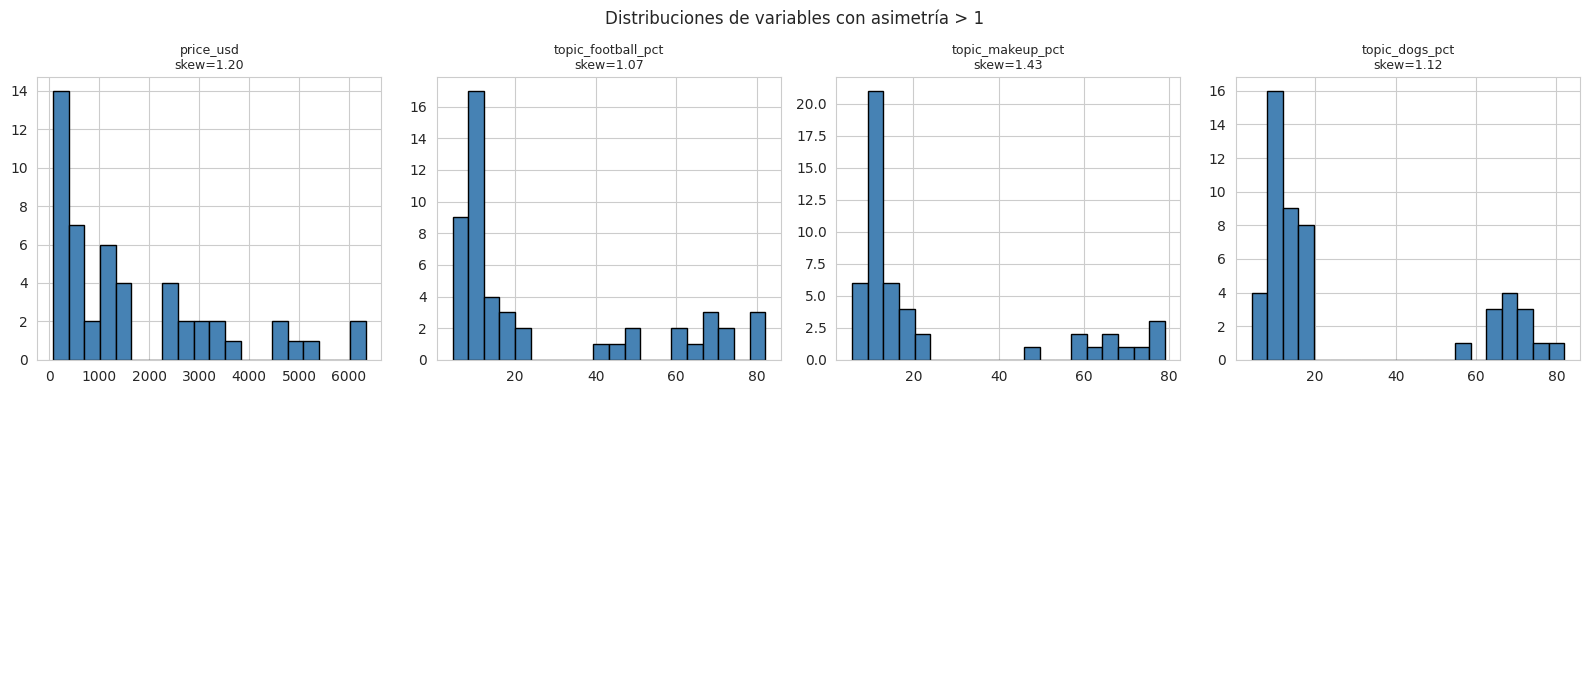

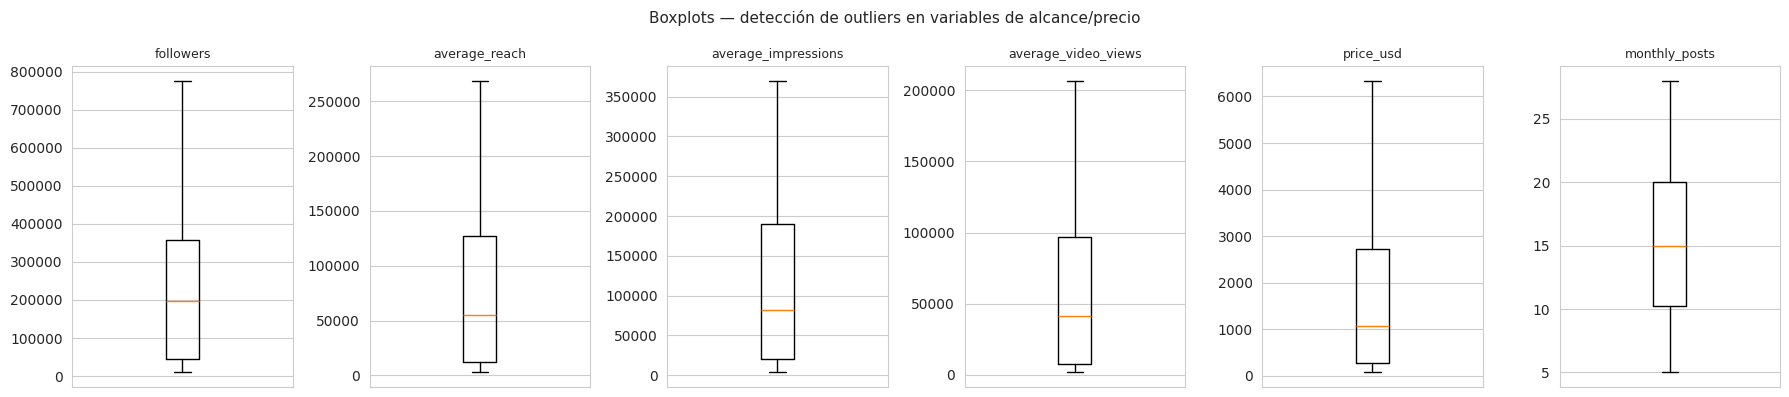


=== Outliers por IQR (1.5 regla) ===
topic_makeup_pct     11
comments_per_1000     1
likes_per_1000        1
shares_per_1000       1
dtype: int64

=== Pares con |correlación| > 0.9 ===
  average_reach                  <-> average_video_views             r = +0.997
  average_impressions            <-> average_video_views             r = +0.988
  average_reach                  <-> average_impressions             r = +0.987
  video_posts_pct                <-> short_form_posts_pct            r = +0.971
  short_form_posts_pct           <-> trend_posts_pct                 r = +0.961
  video_posts_pct                <-> trend_posts_pct                 r = +0.952
  followers                      <-> average_reach                   r = +0.918
  average_impressions            <-> price_usd                       r = +0.915
  followers                      <-> average_impressions             r = +0.912
  average_video_views            <-> price_usd                       r = +0.908
  average_reac

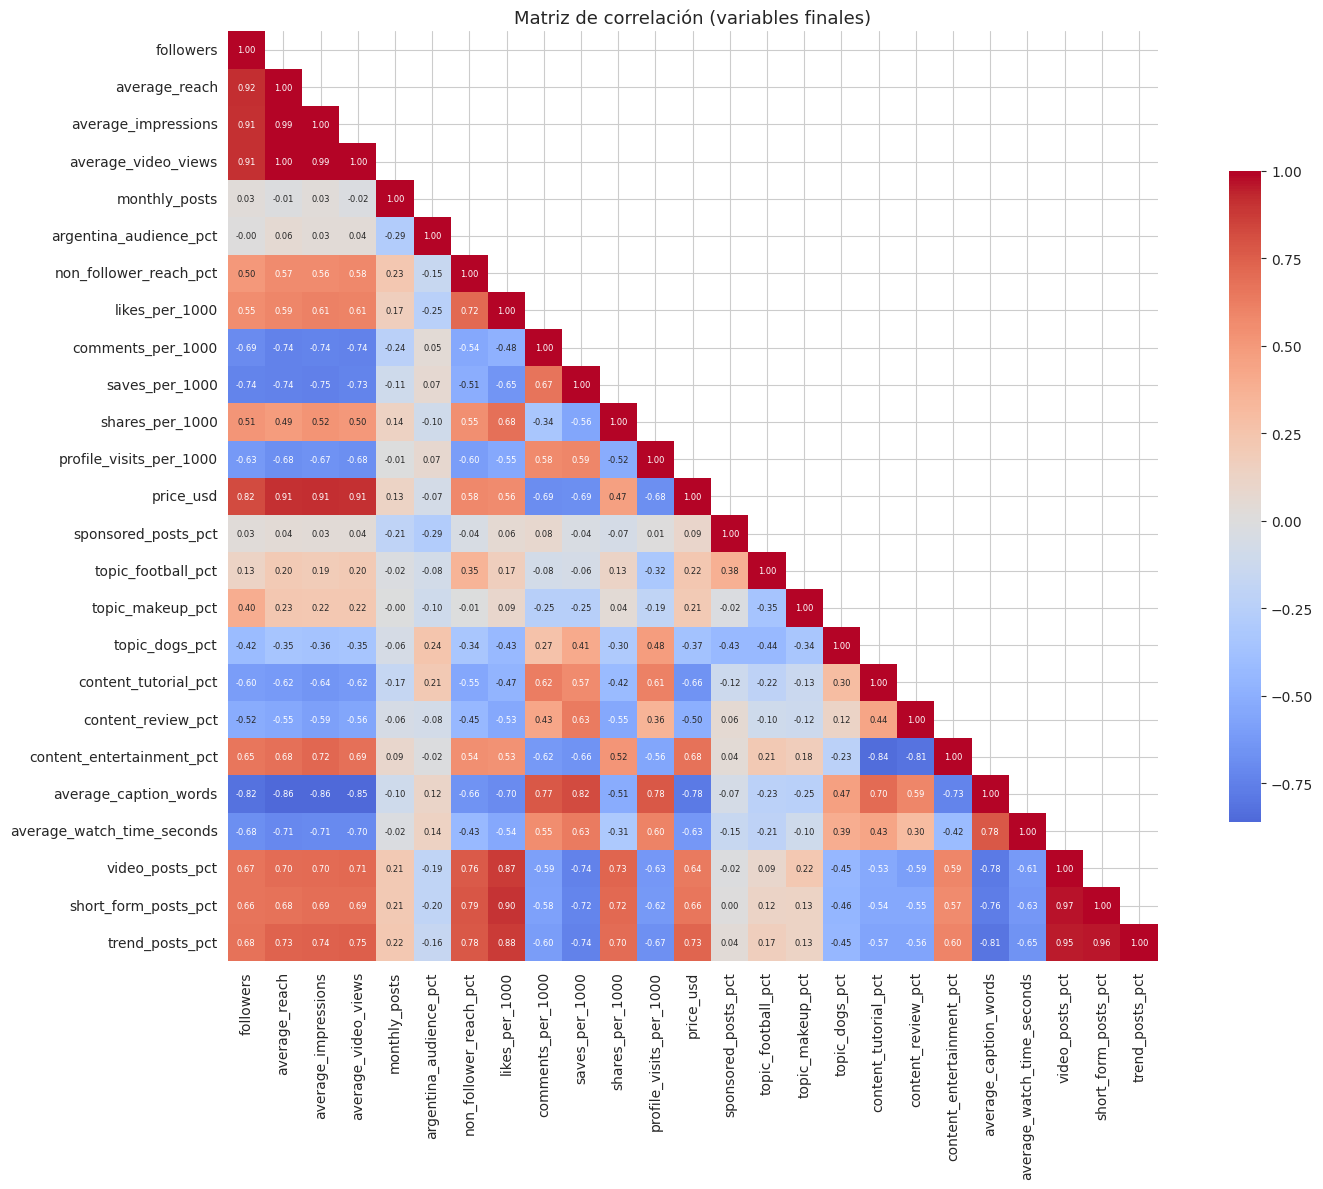


Variables a transformar con log1p (4): ['price_usd', 'topic_football_pct', 'topic_makeup_pct', 'topic_dogs_pct']

Skewness antes / después de log1p:
  price_usd                     : +1.20 -> -0.33
  topic_football_pct            : +1.07 -> +0.64
  topic_makeup_pct              : +1.43 -> +1.01
  topic_dogs_pct                : +1.12 -> +0.70

=== Varianza explicada por componente ===
  PC1: 0.5371  (acum: 0.5371)
  PC2: 0.0782  (acum: 0.6153)
  PC3: 0.0726  (acum: 0.6879)
  PC4: 0.0574  (acum: 0.7453)
  PC5: 0.0451  (acum: 0.7904)
  PC6: 0.0411  (acum: 0.8315)
  PC7: 0.0318  (acum: 0.8633)
  PC8: 0.0253  (acum: 0.8886)
  PC9: 0.0193  (acum: 0.9079)
  PC10: 0.0186  (acum: 0.9265)

Criterios de retención:
  Kaiser (eigenvalue > 1):        6 componentes
  Varianza acumulada >= 80%:      6 componentes
  Varianza acumulada >= 90%:      9 componentes
  Codo (mayor caída relativa):    3 componentes


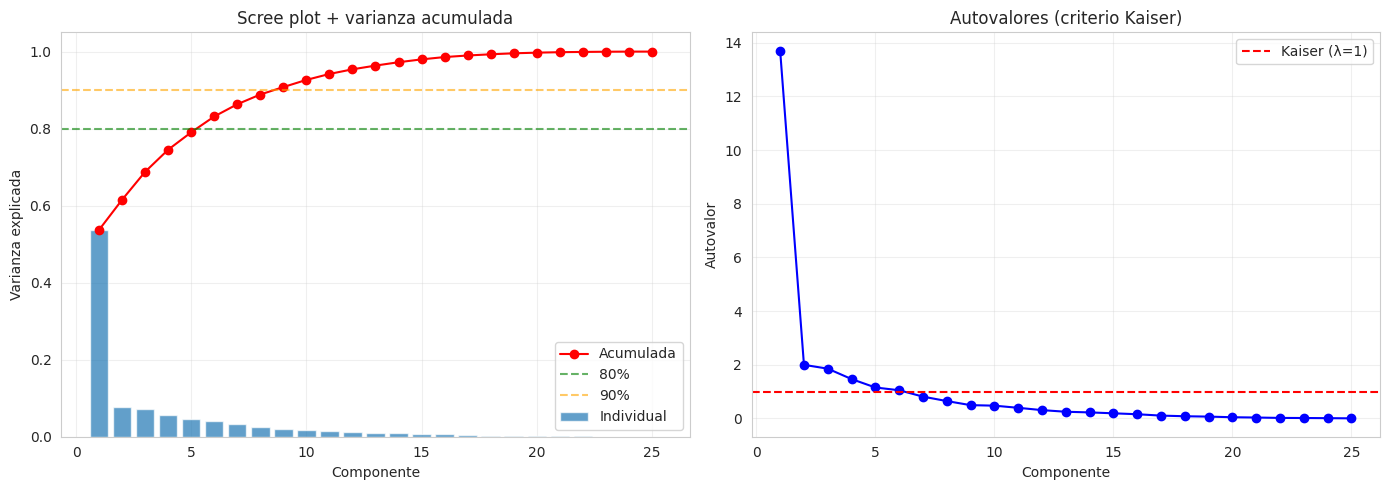


Shapes -> features: 25, loadings: (25, 6)

=== Loadings PC1 (ordenados por valor) ===
average_caption_words         0.954
saves_per_1000                0.854
profile_visits_per_1000       0.785
comments_per_1000             0.774
average_watch_time_seconds    0.746
content_tutorial_pct          0.739
content_review_pct            0.660
topic_dogs_pct                0.523
argentina_audience_pct        0.130
sponsored_posts_pct          -0.061
monthly_posts                -0.152
topic_makeup_pct             -0.192
topic_football_pct           -0.242
shares_per_1000              -0.676
non_follower_reach_pct       -0.754
content_entertainment_pct    -0.789
likes_per_1000               -0.812
followers                    -0.872
short_form_posts_pct         -0.889
video_posts_pct              -0.895
average_reach                -0.909
average_video_views          -0.912
trend_posts_pct              -0.915
average_impressions          -0.917
price_usd                    -0.949
Name: PC1, dt

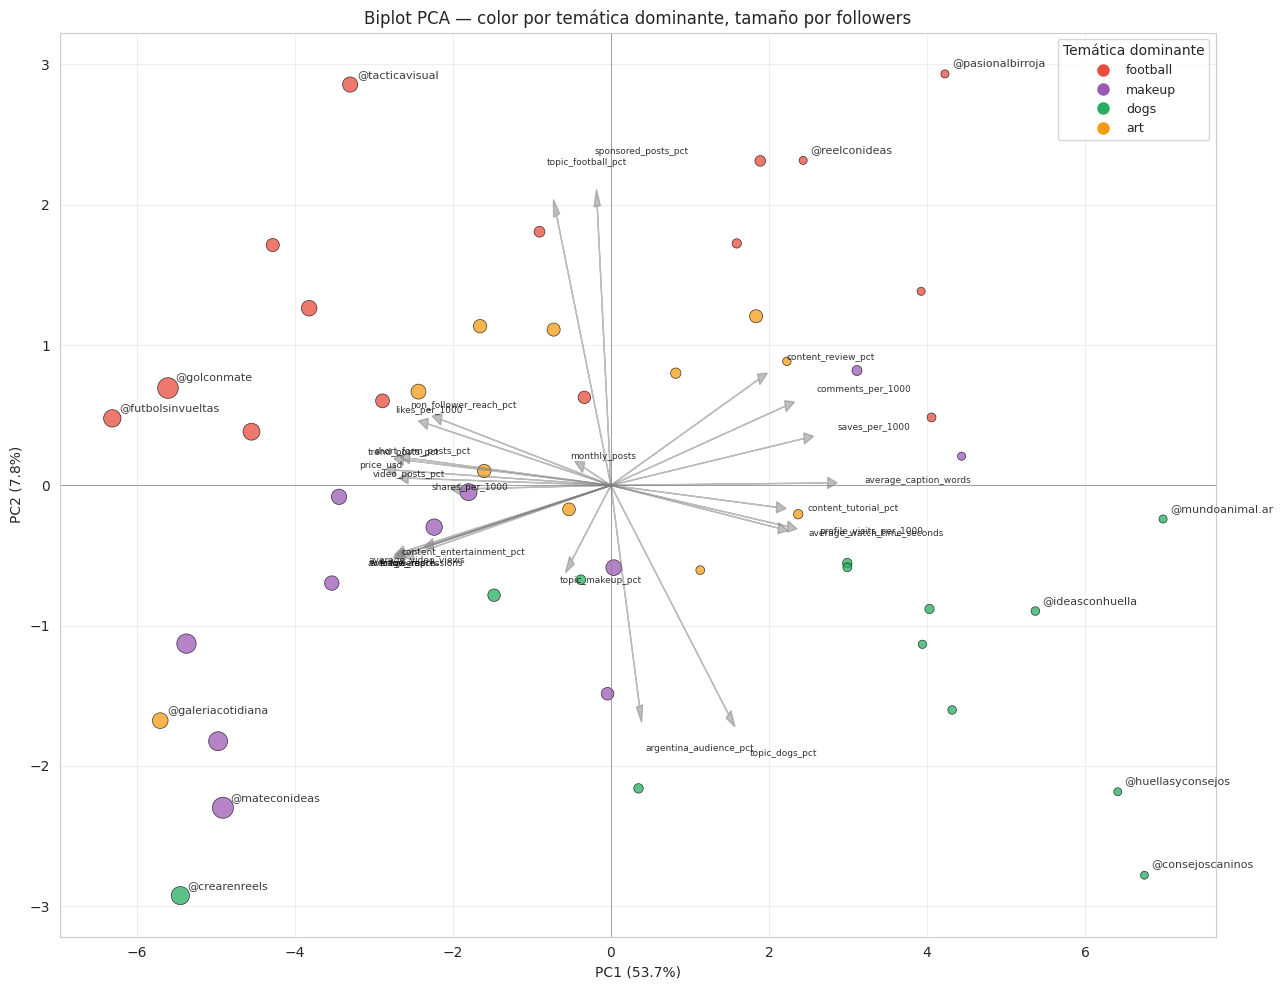


Artefactos guardados en ej1_pca.pkl
Reutilizables en Ej.2 y Ej.3 con: joblib.load('ej1_pca.pkl')


In [ ]:
# ============================================================
# EJERCICIO 1: EDA + PCA
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import joblib

sns.set_style("whitegrid")

# ------------------------------------------------------------
# 1. Carga de datos
# ------------------------------------------------------------
data_path = None
for candidate in ["datos/creadores.csv", "creadores.csv"]:
    if os.path.exists(candidate):
        data_path = candidate
        break

if data_path is None:
    from google.colab import files
    print("Subí el archivo creadores.csv")
    uploaded = files.upload()
    data_path = list(uploaded.keys())[0]

df = pd.read_csv(data_path)
print(f"Cargado desde: {data_path}")
print(f"Dimensiones: {df.shape}")

# ------------------------------------------------------------
# 2. Valores faltantes (verificación completa)
# ------------------------------------------------------------
nulos = df.isna().sum()
print("\n=== Valores faltantes por columna ===")
print(nulos[nulos > 0] if (nulos > 0).any() else "No hay valores faltantes.")
print(f"Total de celdas nulas: {nulos.sum()}")

# ------------------------------------------------------------
# 3. Exclusión de variables derivadas / redundantes conocidas
# ------------------------------------------------------------
drop_derivadas = [
    'creator_id', 'name',
    'price_ars',                  # = price_usd * 1500
    'estimated_argentina_reach',  # = average_reach * arg_audience_pct / 100
    'total_engagement_per_1000',  # = suma de likes+comments+saves+shares
    'organic_posts_pct'           # = 100 - sponsored_posts_pct
]

# ------------------------------------------------------------
# 4. Colinealidad perfecta en topic_* y content_* (suman 100)
# ------------------------------------------------------------
topic_cols = [c for c in df.columns if c.startswith('topic_') and c not in drop_derivadas]
content_cols = [c for c in df.columns if c.startswith('content_') and c not in drop_derivadas]

print("\n=== Suma de grupos temáticos ===")
print("topic_* suman:", df[topic_cols].sum(axis=1).describe()[['min','max','mean']].round(2).to_dict())
print("content_* suman:", df[content_cols].sum(axis=1).describe()[['min','max','mean']].round(2).to_dict())

def eigen_check(frame, cols):
    return np.linalg.eigvalsh(frame[cols].corr().values)

print("\nAutovalores de la matriz de correlación:")
print("  topic_*:   ", np.round(eigen_check(df, topic_cols), 4))
print("  content_*: ", np.round(eigen_check(df, content_cols), 4))

topic_drop = df[topic_cols].var().idxmin()
content_drop = df[content_cols].var().idxmin()
print(f"\nSe elimina de topic_*:   {topic_drop}")
print(f"Se elimina de content_*: {content_drop}")

# ------------------------------------------------------------
# 5. Definición FINAL de features y reasignación de X
# ------------------------------------------------------------
drop_cols_final = drop_derivadas + [topic_drop, content_drop]
features = [c for c in df.columns if c not in drop_cols_final]
print(f"\nVariables finales seleccionadas: {len(features)}")

# *** ESTA ES LA LÍNEA QUE FALTABA ***
X = df[features].copy()
assert X.shape[1] == len(features), f"X tiene {X.shape[1]} columnas, features {len(features)}"

# ------------------------------------------------------------
# 6. Estadísticas descriptivas + skewness sobre X final
# ------------------------------------------------------------
stats = X.describe().T
stats['skew'] = X.skew()
stats['kurtosis'] = X.kurtosis()
stats = stats[['mean', 'std', 'min', '50%', 'max', 'skew', 'kurtosis']]

print("\n=== Estadísticas descriptivas ===")
print(stats.round(2))

skewed_vars = stats[stats['skew'].abs() > 1].index.tolist()
print(f"\nVariables con |skew| > 1 ({len(skewed_vars)}):")
for v in skewed_vars:
    print(f"  {v}: skew = {stats.loc[v,'skew']:.2f}")

# ------------------------------------------------------------
# 7. EDA: distribuciones y outliers
# ------------------------------------------------------------
n_show = min(len(skewed_vars), 8)
if n_show > 0:
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    axes = axes.flatten()
    last = 0
    for i, var in enumerate(skewed_vars[:n_show]):
        axes[i].hist(X[var], bins=20, color='steelblue', edgecolor='black')
        axes[i].set_title(f'{var}\nskew={stats.loc[var,"skew"]:.2f}', fontsize=9)
        last = i
    for j in range(last+1, len(axes)):
        axes[j].axis('off')
    plt.suptitle('Distribuciones de variables con asimetría > 1', fontsize=12)
    plt.tight_layout()
    plt.show()

key_vars = [v for v in ['followers','average_reach','average_impressions',
                        'average_video_views','price_usd','monthly_posts']
            if v in X.columns]
if key_vars:
    fig, axes = plt.subplots(1, len(key_vars), figsize=(3*len(key_vars), 4))
    for ax, var in zip(axes, key_vars):
        ax.boxplot(X[var].dropna())
        ax.set_title(var, fontsize=9)
        ax.set_xticks([])
    plt.suptitle('Boxplots — detección de outliers en variables de alcance/precio', fontsize=11)
    plt.tight_layout()
    plt.show()

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()

out_counts = X.apply(iqr_outliers).sort_values(ascending=False)
print("\n=== Outliers por IQR (1.5 regla) ===")
print(out_counts[out_counts > 0])

# ------------------------------------------------------------
# 8. Redundancia fuerte entre variables
# ------------------------------------------------------------
corr_full = X.corr()
pairs = []
for i, c1 in enumerate(features):
    for c2 in features[i+1:]:
        r = corr_full.loc[c1, c2]
        if abs(r) > 0.9:
            pairs.append((c1, c2, r))
pairs.sort(key=lambda x: -abs(x[2]))

print("\n=== Pares con |correlación| > 0.9 ===")
for c1, c2, r in pairs:
    print(f"  {c1:30s} <-> {c2:30s}  r = {r:+.3f}")

plt.figure(figsize=(16, 12))
mask = np.triu(np.ones_like(corr_full, dtype=bool), k=1)
sns.heatmap(corr_full, mask=mask, cmap='coolwarm', center=0,
            annot=True, fmt='.2f', annot_kws={'size': 6},
            square=True, cbar_kws={'shrink': 0.7})
plt.title('Matriz de correlación (variables finales)', fontsize=13)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Transformación log1p para variables asimétricas positivas
# ------------------------------------------------------------
log_vars = [v for v in skewed_vars if (X[v] >= 0).all() and X[v].min() >= 0]
print(f"\nVariables a transformar con log1p ({len(log_vars)}): {log_vars}")

X_trans = X.copy()
for v in log_vars:
    X_trans[v] = np.log1p(X_trans[v])

skew_after = X_trans[log_vars].skew()
print("\nSkewness antes / después de log1p:")
for v in log_vars:
    print(f"  {v:30s}: {X[v].skew():+.2f} -> {skew_after[v]:+.2f}")

# ------------------------------------------------------------
# 10. Estandarización y PCA
# ------------------------------------------------------------
scaler = StandardScaler()
X_std = scaler.fit_transform(X_trans)

pca = PCA()
pcs = pca.fit_transform(X_std)
eigvals = pca.explained_variance_
explained = pca.explained_variance_ratio_
cum_explained = np.cumsum(explained)

kaiser = int((eigvals > 1).sum())
var_80 = int(np.argmax(cum_explained >= 0.80) + 1)
var_90 = int(np.argmax(cum_explained >= 0.90) + 1)
diffs = np.diff(explained)
elbow = int(np.argmax(diffs[:-1] - diffs[1:]) + 2) if len(diffs) > 2 else 2

print("\n=== Varianza explicada por componente ===")
for i in range(min(10, len(explained))):
    print(f"  PC{i+1}: {explained[i]:.4f}  (acum: {cum_explained[i]:.4f})")

print(f"\nCriterios de retención:")
print(f"  Kaiser (eigenvalue > 1):        {kaiser} componentes")
print(f"  Varianza acumulada >= 80%:      {var_80} componentes")
print(f"  Varianza acumulada >= 90%:      {var_90} componentes")
print(f"  Codo (mayor caída relativa):    {elbow} componentes")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(1, len(explained)+1), explained, alpha=0.7, label='Individual')
axes[0].plot(range(1, len(explained)+1), cum_explained, 'ro-', label='Acumulada')
axes[0].axhline(0.80, color='green', ls='--', alpha=0.6, label='80%')
axes[0].axhline(0.90, color='orange', ls='--', alpha=0.6, label='90%')
axes[0].set_xlabel('Componente'); axes[0].set_ylabel('Varianza explicada')
axes[0].set_title('Scree plot + varianza acumulada')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(range(1, len(eigvals)+1), eigvals, 'bo-')
axes[1].axhline(1.0, color='red', ls='--', label='Kaiser (λ=1)')
axes[1].set_xlabel('Componente'); axes[1].set_ylabel('Autovalor')
axes[1].set_title('Autovalores (criterio Kaiser)')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. Loadings (autovectores * sqrt(eigenvalue))
# ------------------------------------------------------------
n_retained = max(kaiser, 2)
# loadings: (n_features, n_retained)
loadings = pca.components_[:n_retained].T * np.sqrt(eigvals[:n_retained])
loadings_df = pd.DataFrame(loadings, index=features,
                            columns=[f'PC{i+1}' for i in range(n_retained)])

# Verificación explícita de shapes
print(f"\nShapes -> features: {len(features)}, loadings: {loadings.shape}")
assert loadings.shape[0] == len(features), "Desajuste entre features y loadings"

print("\n=== Loadings PC1 (ordenados por valor) ===")
print(loadings_df['PC1'].sort_values(ascending=False).round(3))

print("\n=== Loadings PC2 (ordenados por valor) ===")
print(loadings_df['PC2'].sort_values(ascending=False).round(3))

# ------------------------------------------------------------
# 12. Biplot con color por temática y tamaño por followers
# ------------------------------------------------------------
topic_cols_orig = [c for c in df.columns if c.startswith('topic_')]
dominant_topic = (df[topic_cols_orig].idxmax(axis=1)
                    .str.replace('topic_', '', regex=False)
                    .str.replace('_pct', '', regex=False))
theme_palette = {'football': '#e74c3c', 'makeup': '#9b59b6',
                 'dogs': '#27ae60', 'art': '#f39c12'}
colors = dominant_topic.map(theme_palette)

sizes = 30 + 200 * (df['followers'] / df['followers'].max())

fig, ax = plt.subplots(figsize=(13, 10))
ax.scatter(pcs[:, 0], pcs[:, 1], c=colors, s=sizes,
           alpha=0.75, edgecolors='black', linewidth=0.5)

# Etiquetas solo para extremos
extreme_idx = (set(np.argsort(pcs[:, 0])[:4]) | set(np.argsort(pcs[:, 0])[-4:]) |
               set(np.argsort(pcs[:, 1])[:3]) | set(np.argsort(pcs[:, 1])[-3:]))
for i in extreme_idx:
    ax.annotate(df['name'].iloc[i], (pcs[i, 0], pcs[i, 1]),
                fontsize=8, alpha=0.9,
                xytext=(5, 5), textcoords='offset points')

# Flechas de variables
scale = 3.0
for i, feat in enumerate(features):
    ax.arrow(0, 0,
             loadings[i, 0] * scale, loadings[i, 1] * scale,
             color='gray', alpha=0.5, head_width=0.08, length_includes_head=True)
    ax.text(loadings[i, 0] * scale * 1.12,
            loadings[i, 1] * scale * 1.12,
            feat, color='black', fontsize=6.5, alpha=0.8)

from matplotlib.lines import Line2D
legend_theme = [Line2D([0], [0], marker='o', color='w',
                        markerfacecolor=c, markersize=10, label=t)
                for t, c in theme_palette.items()]
ax.legend(handles=legend_theme, title='Temática dominante',
          loc='upper right', fontsize=9)

ax.axhline(0, color='gray', lw=0.5); ax.axvline(0, color='gray', lw=0.5)
ax.set_xlabel(f'PC1 ({explained[0]:.1%})')
ax.set_ylabel(f'PC2 ({explained[1]:.1%})')
ax.set_title('Biplot PCA — color por temática dominante, tamaño por followers', fontsize=12)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 13. Persistencia para Ejercicios 2 y 3
# ------------------------------------------------------------
joblib.dump({
    'features': features,
    'log_vars': log_vars,
    'scaler': scaler,
    'X_std': X_std,
    'X_trans': X_trans,
    'pca': pca,
    'pcs': pcs,
    'explained': explained,
    'loadings': loadings_df,
    'eigvals': eigvals,
    'n_retained': n_retained,
    'dominant_topic': dominant_topic,
    'df_names': df['name'].values
}, 'ej1_pca.pkl')

print("\nArtefactos guardados en ej1_pca.pkl")
print("Reutilizables en Ej.2 y Ej.3 con: joblib.load('ej1_pca.pkl')")

X_std: 50 creadores, 25 dimensiones
Features: ['followers', 'average_reach', 'average_impressions', 'average_video_views', 'monthly_posts', 'argentina_audience_pct', 'non_follower_reach_pct', 'likes_per_1000', 'comments_per_1000', 'saves_per_1000', 'shares_per_1000', 'profile_visits_per_1000', 'price_usd', 'sponsored_posts_pct', 'topic_football_pct', 'topic_makeup_pct', 'topic_dogs_pct', 'content_tutorial_pct', 'content_review_pct', 'content_entertainment_pct', 'average_caption_words', 'average_watch_time_seconds', 'video_posts_pct', 'short_form_posts_pct', 'trend_posts_pct']

Barrido: 48 configuraciones x 3 semillas

=== Top 10 configuraciones (ordenadas por score combinado) ===
 k  eta0  radius0       decay  QE_mean  QE_std  QE2_mean  TE_mean  TE_std  dead_mean  score
 6   1.0      3.0 exponential   1.4694  0.0313    2.6960   0.3200  0.1143     4.0000 2.1396
 6   1.0      3.0      linear   1.6691  0.0068    3.2042   0.2467  0.0573     2.3333 2.1975
 6   0.5      3.0 exponential   1.7

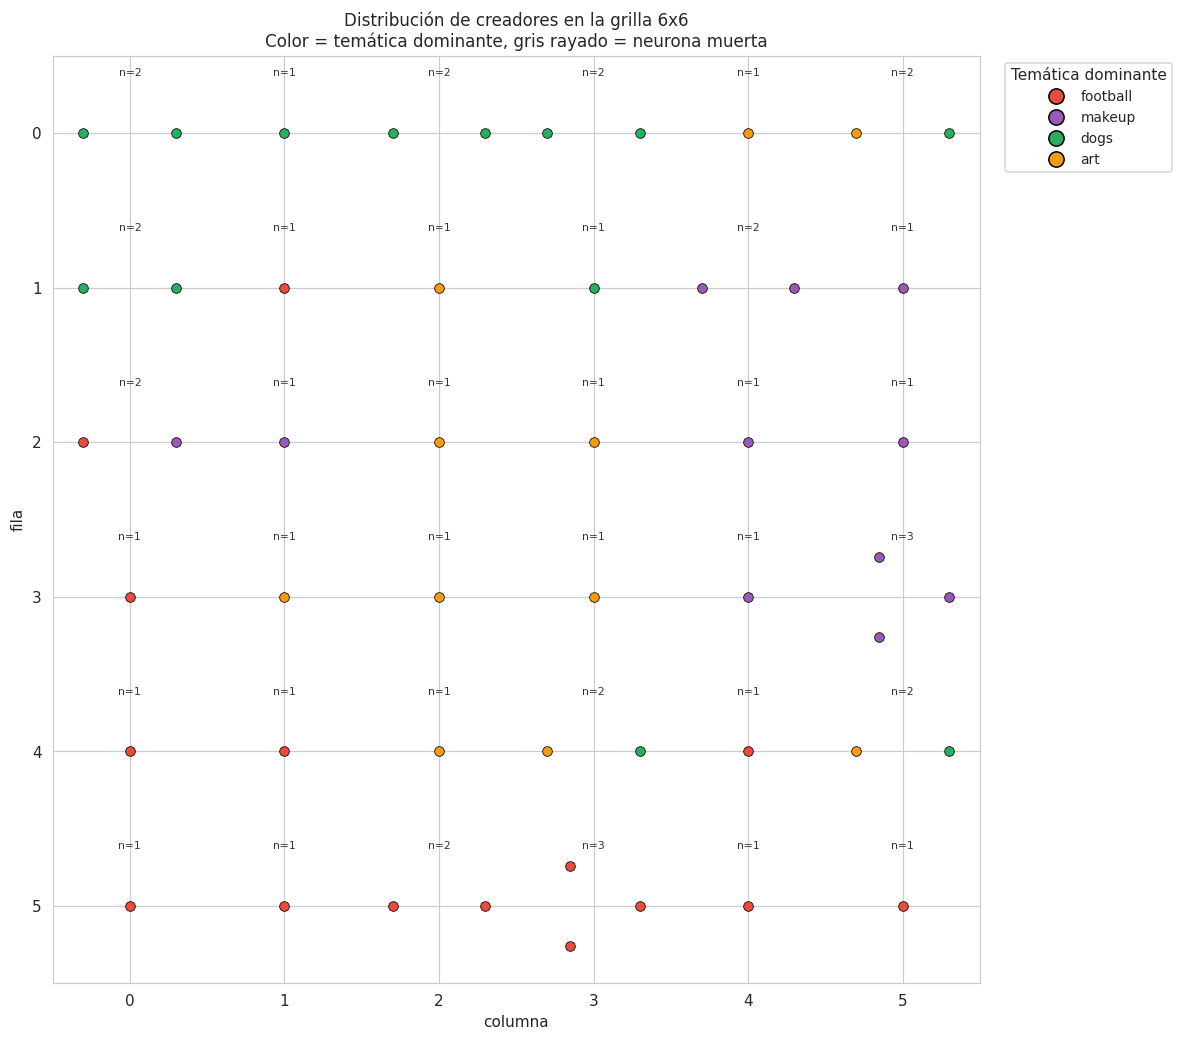

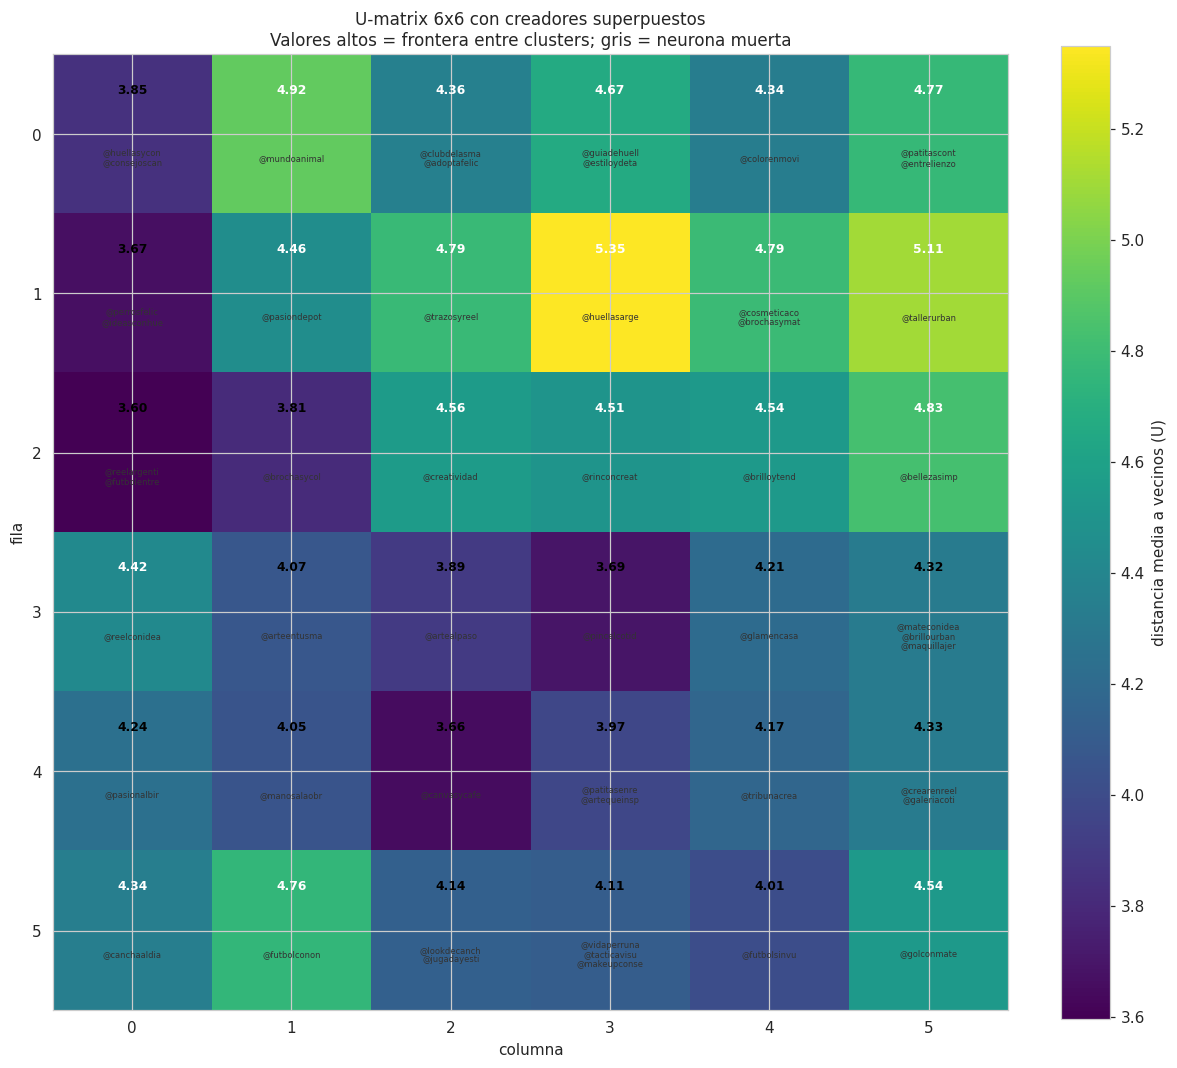

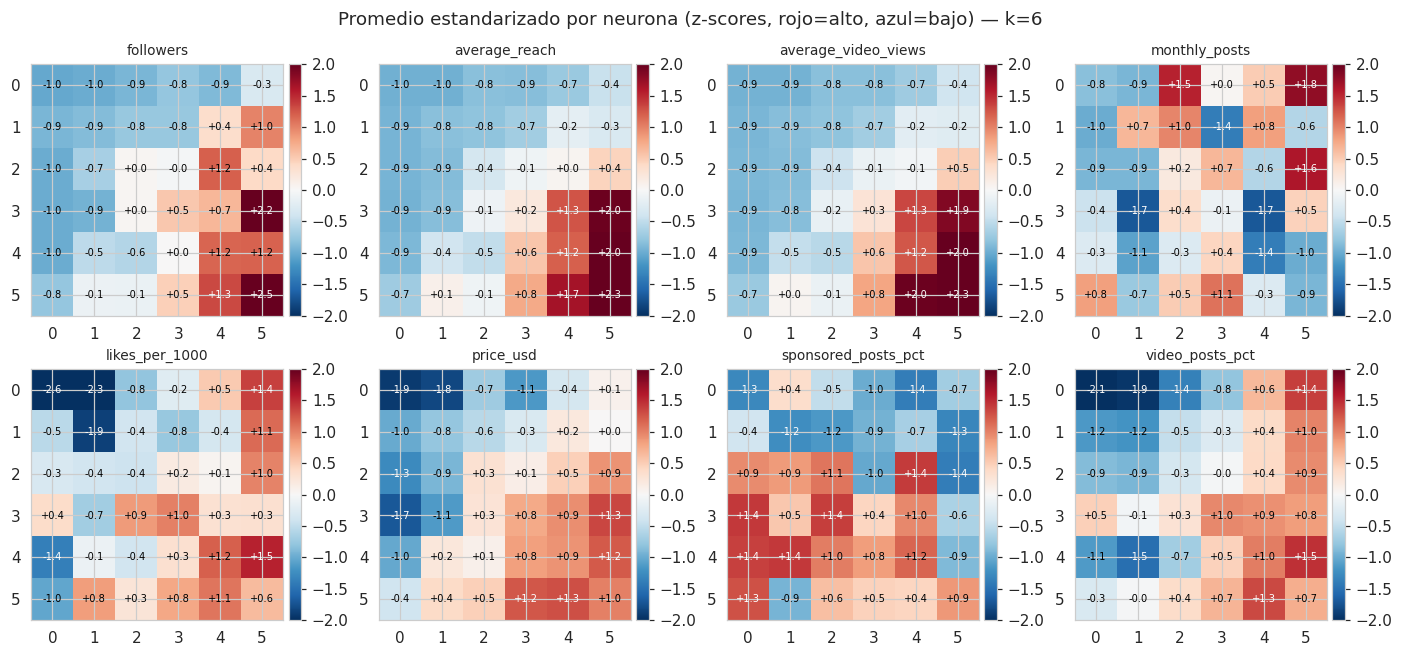

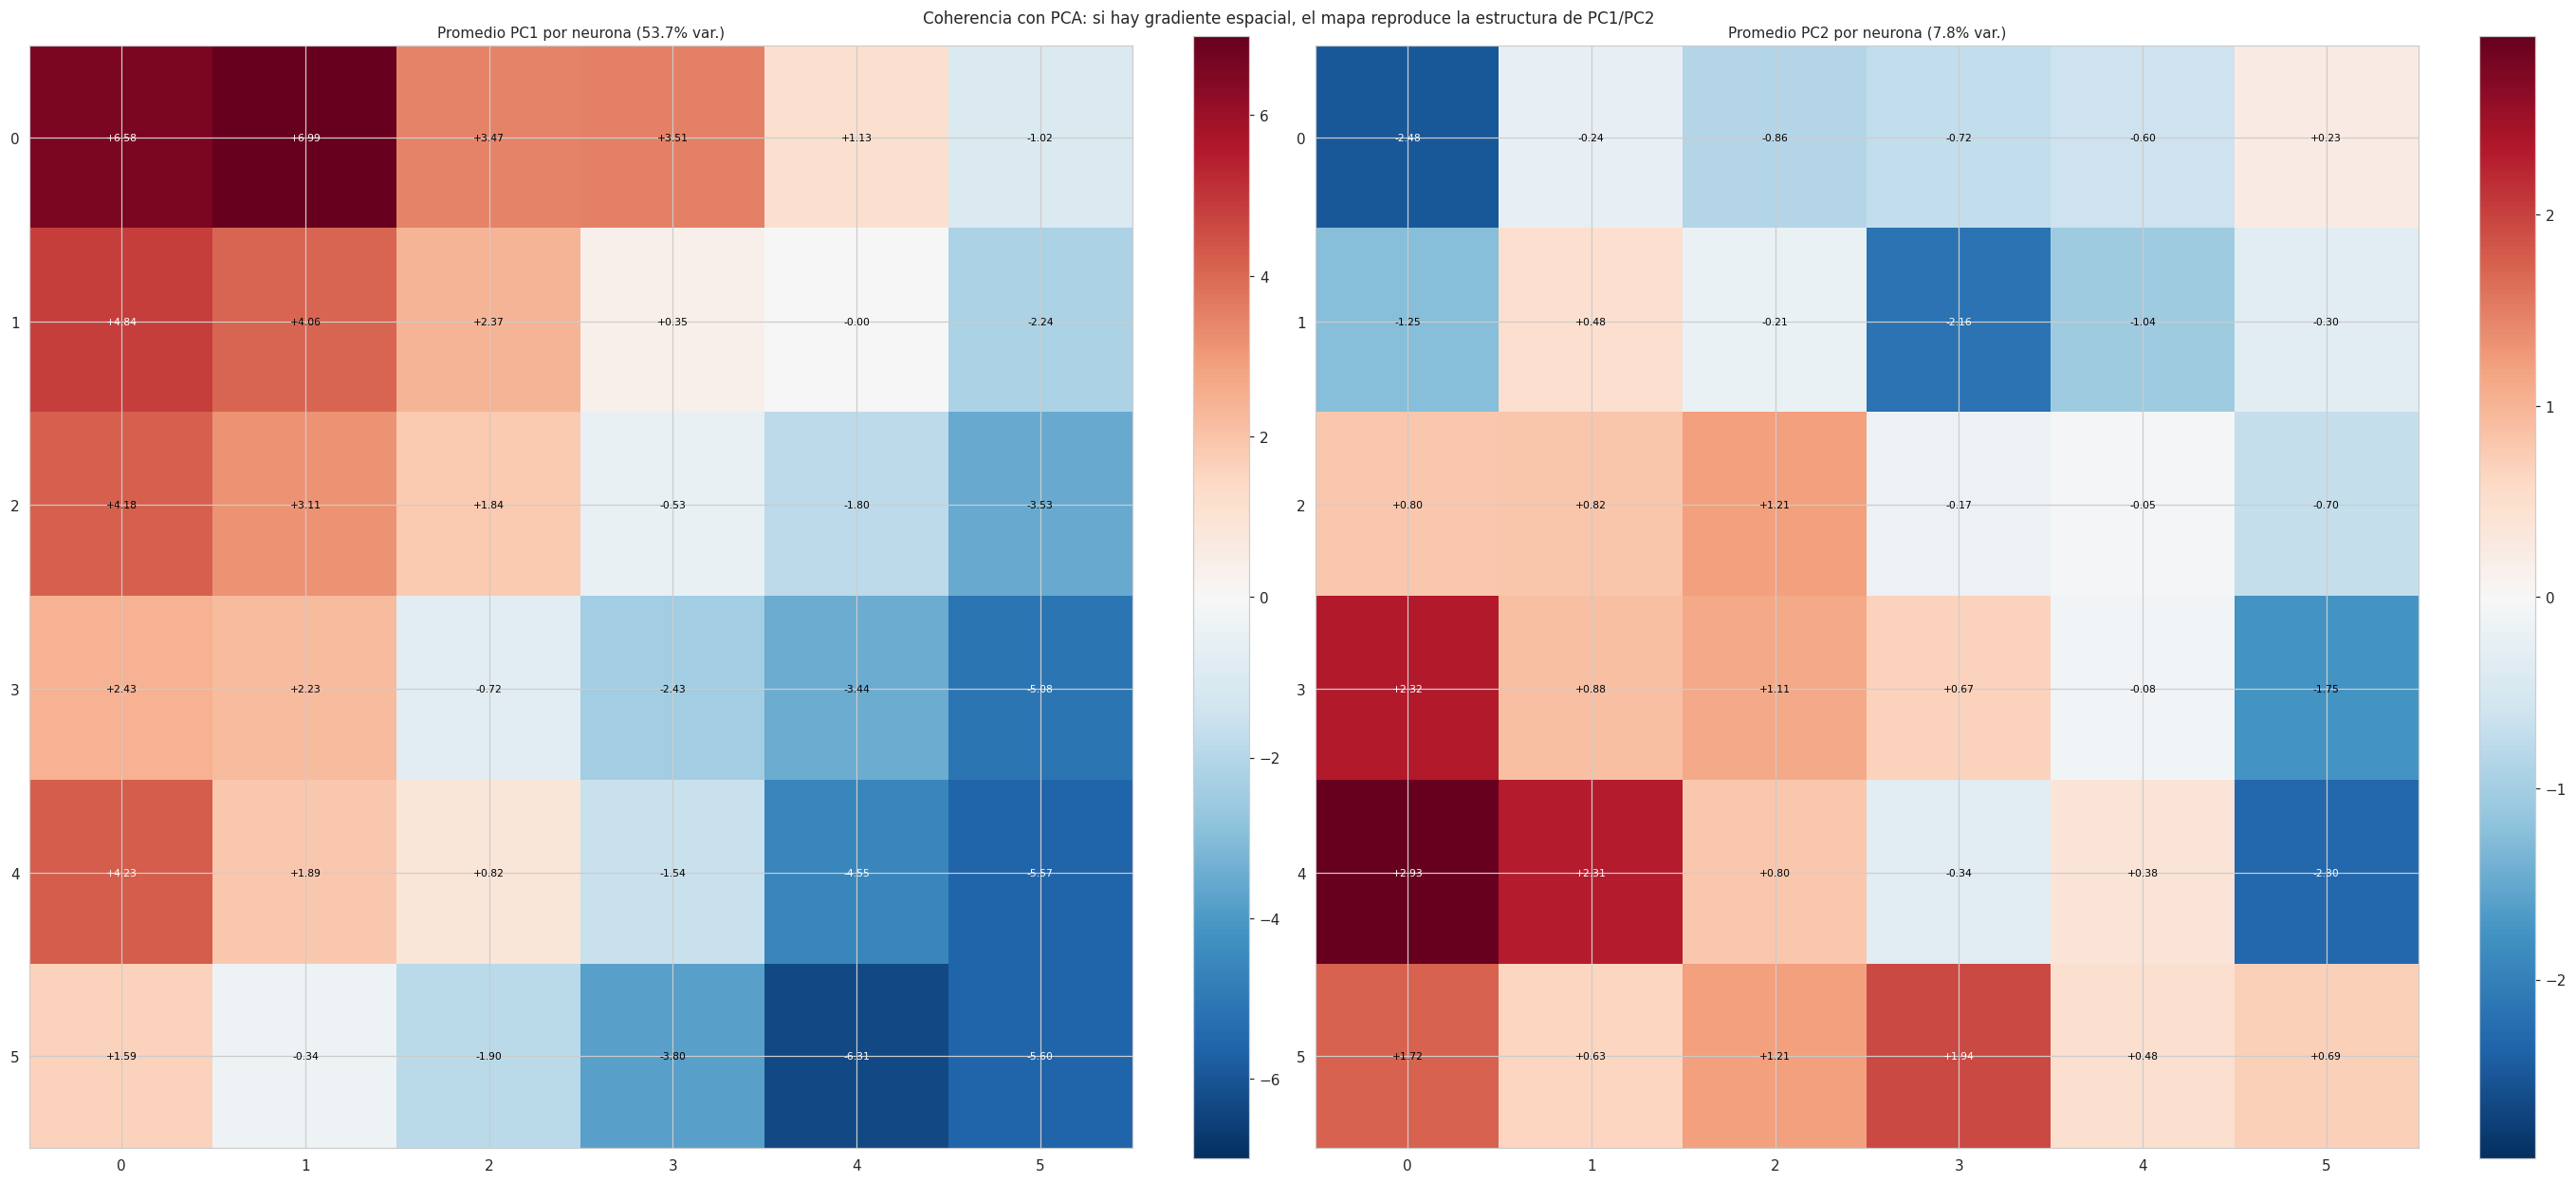

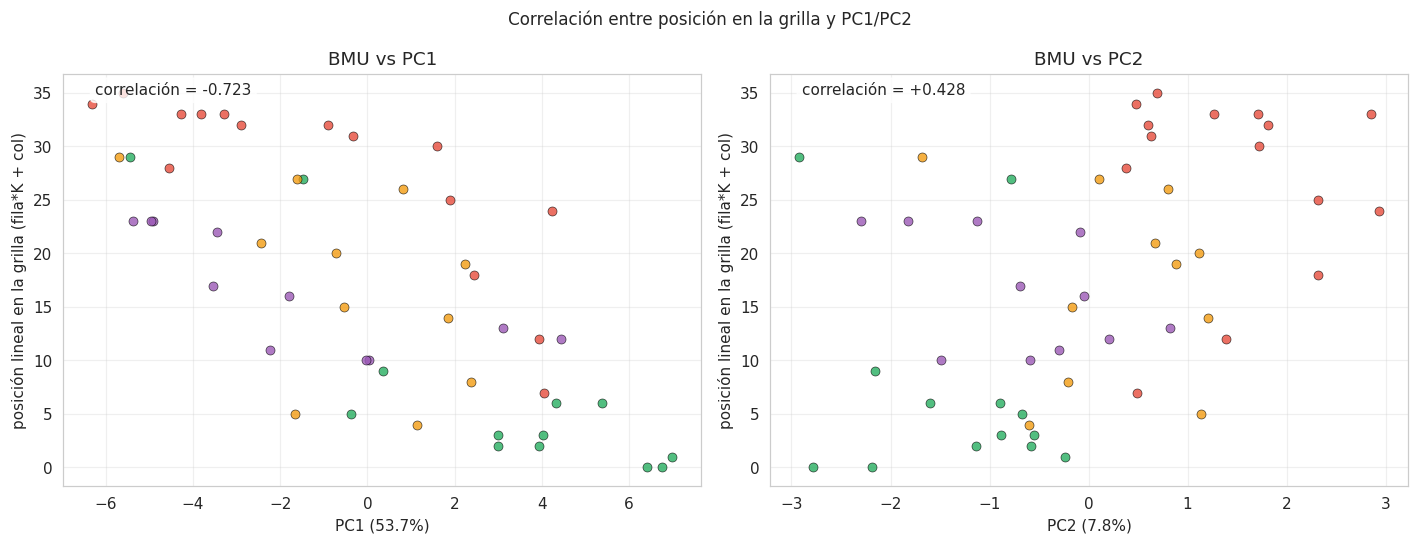


=== Perfil estandarizado por neurona activa ===
(z-scores: +2 = muy por encima de la media, -2 = muy por debajo)

Celda (0,0) — 2 creadores: @huellasyconsejos, @consejoscaninos
  Alto en: argentina_audience_pct (+1.71), topic_dogs_pct (+1.65), average_caption_words (+1.60)
  Bajo en: likes_per_1000 (-2.62), short_form_posts_pct (-2.13), video_posts_pct (-2.07)
Celda (0,1) — 1 creadores: @mundoanimal.ar
  Alto en: profile_visits_per_1000 (+2.28), saves_per_1000 (+2.22), content_review_pct (+1.98)
  Bajo en: likes_per_1000 (-2.27), short_form_posts_pct (-2.12), trend_posts_pct (-1.95)
Celda (0,2) — 2 creadores: @clubdelasmascotas, @adoptafelicidad
  Alto en: topic_dogs_pct (+1.61), average_watch_time_seconds (+1.59), monthly_posts (+1.53)
  Bajo en: video_posts_pct (-1.35), short_form_posts_pct (-1.22), trend_posts_pct (-1.10)
Celda (0,3) — 2 creadores: @guiadehuellas, @estiloydetalle
  Alto en: saves_per_1000 (+1.65), topic_dogs_pct (+1.59), comments_per_1000 (+1.15)
  Bajo en: price_u

In [ ]:
# ============================================================
# EJERCICIO 2: Red de Kohonen
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from itertools import product

plt.rcParams['figure.dpi'] = 110
rng_global = np.random.default_rng(0)

# ------------------------------------------------------------
# 1. Cargar artefactos del Ej1 (preprocesamiento consistente)
# ------------------------------------------------------------
if not os.path.exists('ej1_pca.pkl'):
    raise FileNotFoundError("Ejecutá primero el Ejercicio 1 para generar ej1_pca.pkl")

art = joblib.load('ej1_pca.pkl')
X_std        = art['X_std']              # (N, D) estandarizado y log-transformado
features     = art['features']
pcs          = art['pcs']                # (N, n_comp) scores PCA
explained    = art['explained']
dominant_topic = art['dominant_topic']   # Series con la temática dominante por creador
df_names     = art['df_names']

# Necesitamos también el dataframe original para followers y para leer temáticas
data_path = None
for cand in ["datos/creadores.csv", "creadores.csv"]:
    if os.path.exists(cand):
        data_path = cand; break
if data_path is None:
    from google.colab import files
    print("Subí creadores.csv"); up = files.upload(); data_path = list(up.keys())[0]
df = pd.read_csv(data_path)

N, D = X_std.shape
print(f"X_std: {N} creadores, {D} dimensiones")
print(f"Features: {features}")

# ------------------------------------------------------------
# 2. Kohonen vectorizado con schedules correctos y vecindad gaussiana
# ------------------------------------------------------------
class Kohonen:
    def __init__(self, k=5, eta0=0.5, radius0=None, decay='linear', seed=0):
        self.k = k
        self.eta0 = eta0
        self.radius0 = radius0 if radius0 is not None else k / 2.0
        self.decay = decay
        self.seed = seed

    def fit(self, X, n_iter=3000):
        rng = np.random.default_rng(self.seed)
        N, D = X.shape
        k = self.k

        # Inicialización basada en muestras (más estable que ruido gaussiano)
        idx = rng.choice(N, k * k, replace=False)
        self.W = X[idx].reshape(k, k, D).copy()

        gi, gj = np.meshgrid(np.arange(k), np.arange(k), indexing='ij')

        for t in range(n_iter):
            frac = t / n_iter
            if self.decay == 'linear':
                eta = self.eta0 * (1.0 - frac)
                R   = self.radius0 * (1.0 - frac)      # puede bajar de 1 al final
            elif self.decay == 'exponential':
                eta = self.eta0 * np.exp(-5.0 * frac)
                R   = self.radius0 * np.exp(-5.0 * frac)
            else:  # 'inverse'
                eta = self.eta0 / (1.0 + t)
                R   = max(1.0, self.radius0 / (1.0 + t))

            # Muestra aleatoria
            i = rng.integers(N)
            x = X[i]

            # BMU para x (rápido: k*k*D)
            d = np.linalg.norm(self.W - x, axis=2)
            bi, bj = np.unravel_index(np.argmin(d), d.shape)

            # Vecindad gaussiana
            d2 = (gi - bi) ** 2 + (gj - bj) ** 2
            h = np.exp(-d2 / (2.0 * R * R + 1e-9))

            # Actualización vectorizada
            self.W += eta * h[..., None] * (x - self.W)

        return self

    def predict(self, X):
        """Devuelve array (N, 2) con (i, j) del BMU por muestra."""
        d = np.linalg.norm(X[:, None, None, :] - self.W[None, :, :, :], axis=3)
        flat = d.reshape(len(X), -1)
        idx = flat.argmin(axis=1)
        return np.array(np.unravel_index(idx, (self.k, self.k))).T

    def u_matrix(self, dead_mask=None):
        """Distancia media a vecinos 4-conectados. Ignora neuronas muertas."""
        k = self.k
        U = np.full((k, k), np.nan)
        for i in range(k):
            for j in range(k):
                if dead_mask is not None and dead_mask[i, j]:
                    continue
                neigh = []
                for di, dj in [(-1,0),(1,0),(0,-1),(0,1)]:
                    ni, nj = i+di, j+dj
                    if 0 <= ni < k and 0 <= nj < k:
                        if dead_mask is not None and dead_mask[ni, nj]:
                            continue
                        neigh.append(np.linalg.norm(self.W[i,j] - self.W[ni,nj]))
                if neigh:
                    U[i, j] = np.mean(neigh)
        return U

def quantization_error(W, X):
    """Devuelve (distancia media, distancia media al cuadrado)."""
    d = np.linalg.norm(X[:, None, None, :] - W[None, :, :, :], axis=3)
    min_d = d.reshape(len(X), -1).min(axis=1)
    return float(min_d.mean()), float((min_d**2).mean())

def topographic_error(W, X):
    """Fracción de muestras cuyo 2do BMU no es vecino 4-conectado del 1ro."""
    k = W.shape[0]
    d = np.linalg.norm(X[:, None, None, :] - W[None, :, :, :], axis=3)
    flat = d.reshape(len(X), -1)
    bmu1 = flat.argmin(axis=1)
    flat2 = flat.copy()
    flat2[np.arange(len(X)), bmu1] = np.inf
    bmu2 = flat2.argmin(axis=1)
    i1, j1 = np.unravel_index(bmu1, (k, k))
    i2, j2 = np.unravel_index(bmu2, (k, k))
    not_neighbor = (np.abs(i1 - i2) + np.abs(j1 - j2)) != 1
    return float(not_neighbor.mean())

def count_dead(W, X, k):
    labels = Kohonen(k=k, seed=0)  # solo para usar predict
    labels.W = W
    cells = labels.predict(X)
    used = set(map(tuple, cells))
    dead_mask = np.ones((k, k), dtype=bool)
    for (i, j) in used:
        dead_mask[i, j] = False
    return dead_mask, used

# ------------------------------------------------------------
# 3. Barrido de hiperparámetros con múltiples semillas
# ------------------------------------------------------------
N_ITER_SWEEP = 2000
SEEDS_SWEEP  = [0, 1, 2]

grid = list(product(
    [3, 4, 5, 6],                # k
    [0.1, 0.5, 1.0],             # eta0
    [0.5, 1.0],                  # radius0 factor (radius0 = factor * k)
    ['linear', 'exponential'],   # decay
))

print(f"\nBarrido: {len(grid)} configuraciones x {len(SEEDS_SWEEP)} semillas")

rows = []
for (k, eta0, rfac, decay) in grid:
    qes, qes2, tes, deads = [], [], [], []
    for s in SEEDS_SWEEP:
        net = Kohonen(k=k, eta0=eta0, radius0=rfac*k, decay=decay, seed=s)
        net.fit(X_std, n_iter=N_ITER_SWEEP)
        qe, qe2 = quantization_error(net.W, X_std)
        te = topographic_error(net.W, X_std)
        dm, _ = count_dead(net.W, X_std, k)
        qes.append(qe); qes2.append(qe2); tes.append(te)
        deads.append(dm.sum())
    rows.append({
        'k': k, 'eta0': eta0, 'radius0': rfac*k, 'decay': decay,
        'QE_mean': np.mean(qes), 'QE_std': np.std(qes),
        'QE2_mean': np.mean(qes2),
        'TE_mean': np.mean(tes), 'TE_std': np.std(tes),
        'dead_mean': np.mean(deads)
    })

res = pd.DataFrame(rows)
res['score'] = res['QE_mean'] * (1 + res['TE_mean']) + 0.05 * res['dead_mean']
res = res.sort_values('score')

print("\n=== Top 10 configuraciones (ordenadas por score combinado) ===")
print(res.head(10).round(4).to_string(index=False))

# ------------------------------------------------------------
# 4. Modelo final: mejor config, 5 semillas, más iteraciones
# ------------------------------------------------------------
best = res.iloc[0]
K      = int(best['k'])
ETA    = float(best['eta0'])
RAD    = float(best['radius0'])
DECAY  = best['decay']
N_ITER_FINAL = 6000
SEEDS_FINAL  = [0, 1, 2, 3, 4]

print(f"\nMejor config: k={K}, eta0={ETA}, radius0={RAD}, decay={DECAY}")

# Entrenar con varias semillas y elegir la de menor QE
results_final = []
for s in SEEDS_FINAL:
    net = Kohonen(k=K, eta0=ETA, radius0=RAD, decay=DECAY, seed=s)
    net.fit(X_std, n_iter=N_ITER_FINAL)
    qe, qe2 = quantization_error(net.W, X_std)
    te = topographic_error(net.W, X_std)
    results_final.append((s, qe, qe2, te, net))

qes_final = np.array([r[1] for r in results_final])
tes_final = np.array([r[3] for r in results_final])
print(f"\nModelo final (k={K}, {len(SEEDS_FINAL)} semillas, {N_ITER_FINAL} iter):")
print(f"  QE (distancia media):  {qes_final.mean():.4f} +/- {qes_final.std():.4f}")
print(f"  TE (error topográfico): {tes_final.mean():.4f} +/- {tes_final.std():.4f}")

# Nos quedamos con la mejor semilla para visualización
best_seed, best_qe, _, best_te, net = min(results_final, key=lambda x: x[1])
print(f"  Mejor semilla: {best_seed} (QE={best_qe:.4f}, TE={best_te:.4f})")

labels = net.predict(X_std)                # (N, 2)
dead_mask, used_cells = count_dead(net.W, X_std, K)
print(f"  Neuronas activas: {K*K - dead_mask.sum()}/{K*K}")

U = net.u_matrix(dead_mask=dead_mask)

# ------------------------------------------------------------
# 5. Visualizaciones
# ------------------------------------------------------------
# Paleta por temática
theme_palette = {'football': '#e74c3c', 'makeup': '#9b59b6',
                 'dogs': '#27ae60', 'art': '#f39c12'}

# --- 5.1 Grilla de neuronas con creadores (coloreados por temática) ---
fig, ax = plt.subplots(figsize=(max(8, K*1.8), max(8, K*1.8)))
ax.set_xlim(-0.5, K-0.5); ax.set_ylim(-0.5, K-0.5)
ax.set_aspect('equal'); ax.invert_yaxis()

# Fondo: neuronas muertas en gris
for i in range(K):
    for j in range(K):
        if dead_mask[i, j]:
            ax.add_patch(plt.Rectangle((j-0.5, i-0.5), 1, 1,
                                        facecolor='#e8e8e8', edgecolor='gray',
                                        linewidth=0.8, hatch='//', alpha=0.7))

# Creadores por neurona
cell_creators = {}
for idx_creator, (i, j) in enumerate(labels):
    cell_creators.setdefault((i, j), []).append(idx_creator)

for (i, j), idxs in cell_creators.items():
    n = len(idxs)
    # posiciones distribuidas en la celda
    if n == 1:
        pos = [(j, i)]
    elif n <= 4:
        ang = np.linspace(0, 2*np.pi, n, endpoint=False)
        pos = [(j + 0.3*np.cos(a), i + 0.3*np.sin(a)) for a in ang]
    else:
        ang = np.linspace(0, 2*np.pi, n, endpoint=False)
        r = 0.4
        pos = [(j + r*np.cos(a), i + r*np.sin(a)) for a in ang]
    for k_pos, (px, py) in zip(idxs, pos):
        c = theme_palette.get(dominant_topic.iloc[k_pos], '#999999')
        ax.scatter(px, py, s=40, c=c, edgecolors='black', linewidth=0.5, zorder=5)
    ax.text(j, i - 0.42, f'n={n}', ha='center', va='top',
            fontsize=7, color='#333')

ax.set_xticks(range(K)); ax.set_yticks(range(K))
ax.set_xlabel('columna'); ax.set_ylabel('fila')
ax.set_title(f'Distribución de creadores en la grilla {K}x{K}\n'
             f'Color = temática dominante, gris rayado = neurona muerta', fontsize=11)

legend_theme = [Line2D([0],[0], marker='o', color='w', markerfacecolor=c,
                        markersize=10, label=t, markeredgecolor='black')
                for t, c in theme_palette.items()]
ax.legend(handles=legend_theme, title='Temática dominante',
          loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
plt.tight_layout(); plt.show()

# --- 5.2 U-matrix con creadores superpuestos ---
fig, ax = plt.subplots(figsize=(max(8, K*1.8), max(8, K*1.8)))
cmap_u = plt.cm.viridis.copy()
cmap_u.set_bad('#e8e8e8')

masked_U = np.ma.masked_invalid(U)
im = ax.imshow(masked_U, cmap=cmap_u, origin='upper')
plt.colorbar(im, ax=ax, label='distancia media a vecinos (U)', fraction=0.046)

# Valores numéricos
for i in range(K):
    for j in range(K):
        if not np.isnan(U[i, j]):
            val = U[i, j]
            color = 'white' if val > np.nanmean(U) else 'black'
            ax.text(j, i - 0.28, f'{val:.2f}', ha='center', va='center',
                    fontsize=8, fontweight='bold', color=color)

# Nombres de creadores debajo del valor
for (i, j), idxs in cell_creators.items():
    names_short = [df_names[k][:12] for k in idxs]
    txt = '\n'.join(names_short[:3]) + (f'\n+{len(idxs)-3}' if len(idxs)>3 else '')
    ax.text(j, i + 0.15, txt, ha='center', va='center',
            fontsize=5.5, color='#333', linespacing=1.1)

ax.set_xticks(range(K)); ax.set_yticks(range(K))
ax.set_xlabel('columna'); ax.set_ylabel('fila')
ax.set_title(f'U-matrix {K}x{K} con creadores superpuestos\n'
             f'Valores altos = frontera entre clusters; gris = neurona muerta', fontsize=11)
plt.tight_layout(); plt.show()

# --- 5.3 Mapas por variable (promedio estandarizado por neurona) ---
key_vars = ['followers', 'average_reach', 'average_video_views', 'monthly_posts',
            'total_engagement_per_1000' if 'total_engagement_per_1000' in features else 'likes_per_1000',
            'price_usd' if 'price_usd' in features else features[0],
            'sponsored_posts_pct', 'video_posts_pct']
key_vars = [v for v in key_vars if v in features][:8]

ncols = 4
nrows = (len(key_vars) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*3.2, nrows*3.0))
axes = np.atleast_2d(axes).flatten()

# Diccionario feature -> índice en X_std
feat_to_idx = {f: i for i, f in enumerate(features)}

for ax, var in zip(axes, key_vars):
    v = feat_to_idx[var]
    grid_mean = np.full((K, K), np.nan)
    for (i, j), idxs in cell_creators.items():
        grid_mean[i, j] = X_std[idxs, v].mean()
    masked = np.ma.masked_invalid(grid_mean)
    im = ax.imshow(masked, cmap='RdBu_r',
                   vmin=-2, vmax=2, origin='upper')
    for i in range(K):
        for j in range(K):
            if not np.isnan(grid_mean[i, j]):
                val = grid_mean[i, j]
                tc = 'white' if abs(val) > 1.2 else 'black'
                ax.text(j, i, f'{val:+.1f}', ha='center', va='center',
                        fontsize=6.5, color=tc)
    ax.set_xticks(range(K)); ax.set_yticks(range(K))
    ax.set_title(var, fontsize=9)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.02)

for ax in axes[len(key_vars):]:
    ax.axis('off')
plt.suptitle(f'Promedio estandarizado por neurona (z-scores, rojo=alto, azul=bajo) — k={K}',
             fontsize=12)
plt.tight_layout(); plt.show()

# --- 5.4 Comparación con PC1 / PC2 ---
# Para cada neurona activa, promedio de PC1 y PC2 de sus creadores
grid_pc1 = np.full((K, K), np.nan)
grid_pc2 = np.full((K, K), np.nan)
for (i, j), idxs in cell_creators.items():
    grid_pc1[i, j] = pcs[idxs, 0].mean()
    grid_pc2[i, j] = pcs[idxs, 1].mean()

fig, axes = plt.subplots(1, 2, figsize=(2*K*1.9 + 2, K*1.9))
for ax, grid, name, pct in [
    (axes[0], grid_pc1, 'PC1', explained[0]),
    (axes[1], grid_pc2, 'PC2', explained[1])
]:
    masked = np.ma.masked_invalid(grid)
    vmax = np.nanmax(np.abs(grid))
    im = ax.imshow(masked, cmap='RdBu_r', vmin=-vmax, vmax=vmax, origin='upper')
    for i in range(K):
        for j in range(K):
            if not np.isnan(grid[i, j]):
                val = grid[i, j]
                tc = 'white' if abs(val) > vmax*0.6 else 'black'
                ax.text(j, i, f'{val:+.2f}', ha='center', va='center',
                        fontsize=7, color=tc)
    ax.set_xticks(range(K)); ax.set_yticks(range(K))
    ax.set_title(f'Promedio {name} por neurona ({pct:.1%} var.)', fontsize=10)
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.suptitle('Coherencia con PCA: si hay gradiente espacial, el mapa reproduce la estructura de PC1/PC2',
             fontsize=11)
plt.tight_layout(); plt.show()

# --- 5.5 Dispersión BMU vs PC1/PC2 ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, pc_idx in zip(axes, [0, 1]):
    for (i, j), idxs in cell_creators.items():
        for kc in idxs:
            c = theme_palette.get(dominant_topic.iloc[kc], '#999999')
            ax.scatter(pcs[kc, pc_idx], i*K + j, s=35, c=c,
                       edgecolors='black', linewidth=0.4, alpha=0.8)
    ax.set_xlabel(f'PC{pc_idx+1} ({explained[pc_idx]:.1%})')
    ax.set_ylabel('posición lineal en la grilla (fila*K + col)')
    ax.set_title(f'BMU vs PC{pc_idx+1}')
    ax.grid(alpha=0.3)
    # Correlación
    flat_pos = np.array([i*K + j for (i, j) in labels])
    corr = np.corrcoef(pcs[:, pc_idx], flat_pos)[0, 1]
    ax.text(0.05, 0.95, f'correlación = {corr:+.3f}',
            transform=ax.transAxes, fontsize=10,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
plt.suptitle('Correlación entre posición en la grilla y PC1/PC2', fontsize=11)
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 6. Perfiles estandarizados por neurona activa
# ------------------------------------------------------------
print("\n=== Perfil estandarizado por neurona activa ===")
print("(z-scores: +2 = muy por encima de la media, -2 = muy por debajo)\n")

perfil_rows = []
for (i, j) in sorted(cell_creators.keys()):
    idxs = cell_creators[(i, j)]
    mean_z = X_std[idxs].mean(axis=0)
    # Variables más características: top 3 positivas y top 3 negativas
    order = np.argsort(mean_z)
    top_pos = [(features[k], mean_z[k]) for k in order[-3:][::-1]]
    top_neg = [(features[k], mean_z[k]) for k in order[:3]]
    names = [df_names[k] for k in idxs]
    print(f"Celda ({i},{j}) — {len(idxs)} creadores: {', '.join(names[:4])}"
          + (f" (+{len(names)-4})" if len(names) > 4 else ""))
    print(f"  Alto en: " + ", ".join([f"{f} ({v:+.2f})" for f, v in top_pos]))
    print(f"  Bajo en: " + ", ".join([f"{f} ({v:+.2f})" for f, v in top_neg]))
    perfil_rows.append({'cell': (i,j), 'n': len(idxs), 'names': names})

# Guardar resultados
joblib.dump({
    'k': K, 'eta0': ETA, 'radius0': RAD, 'decay': DECAY,
    'net_W': net.W, 'labels': labels, 'U': U,
    'dead_mask': dead_mask, 'features': features,
    'best_seed': best_seed, 'QE': best_qe, 'TE': best_te
}, 'ej2_kohonen.pkl')
print("\nModelo y resultados guardados en ej2_kohonen.pkl")

X_std: 50 x 25
PC1 explica 53.71% de la varianza

=== Convergencia al final del entrenamiento ===
||w|| final:  1.0024 +/- 0.0000
|cos(w,PC1)|: 0.9999 +/- 0.0000
var(X·w):     13.4911 +/- 0.0008
var PC1 (ref):13.7011


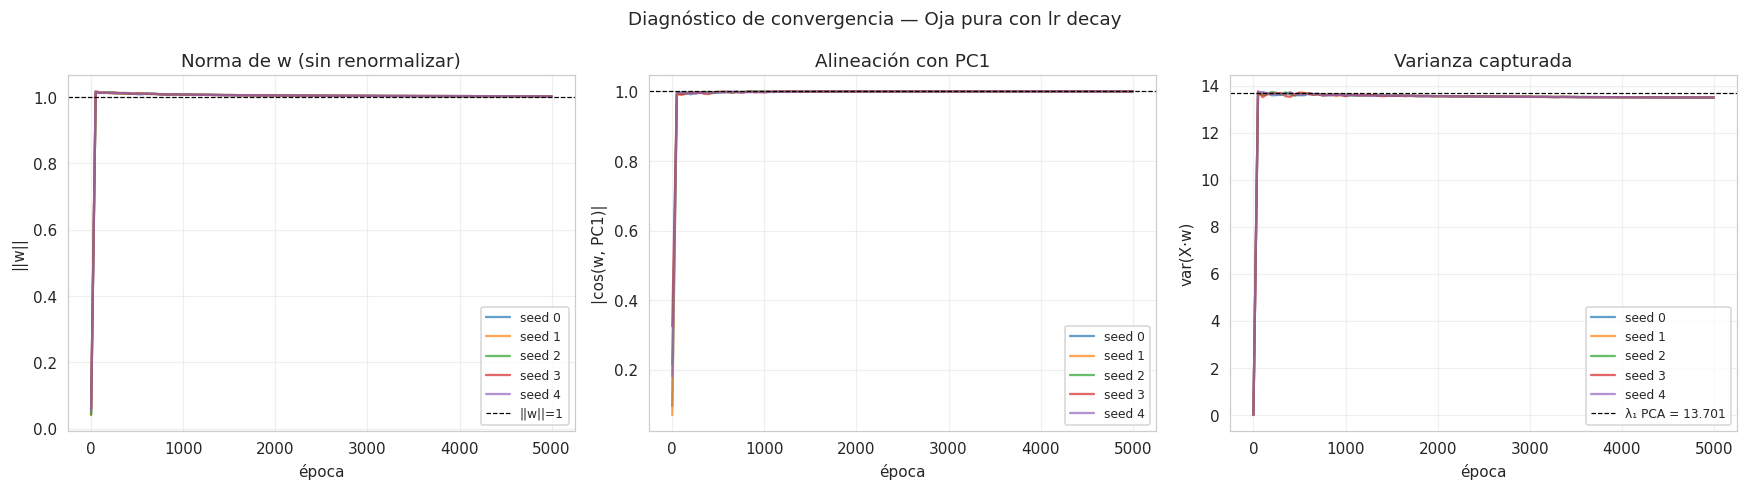


=== Sensibilidad lr × decay (media de 3 semillas) ===
     lr   decay    |cos|   var/w_varPC1
 0.0010  0.0000   0.9999         0.9856
 0.0010  0.0010   1.0000         0.9809
 0.0010  0.0100   1.0000         0.9801
 0.0010  0.1000   1.0000         0.9800
 0.0050  0.0000   0.9947         1.0018
 0.0050  0.0010   0.9999         0.9847
 0.0050  0.0100   1.0000         0.9806
 0.0050  0.1000   1.0000         0.9801
 0.0100  0.0000   0.9838         1.0191
 0.0100  0.0010   0.9996         0.9892
 0.0100  0.0100   1.0000         0.9811
 0.0100  0.1000   1.0000         0.9801


/tmp/ipykernel_32050/324707755.py:73: RuntimeWarning: overflow encountered in multiply
  self.w += eta * y * (x - y * self.w)
/tmp/ipykernel_32050/324707755.py:72: RuntimeWarning: invalid value encountered in matmul
  y = x @ self.w


 0.0500  0.0000      nan            nan
 0.0500  0.0010      nan            nan
 0.0500  0.0100      nan            nan
 0.0500  0.1000   1.0000         0.9806
 0.1000  0.0000      nan            nan
 0.1000  0.0010      nan            nan
 0.1000  0.0100      nan            nan
 0.1000  0.1000      nan            nan


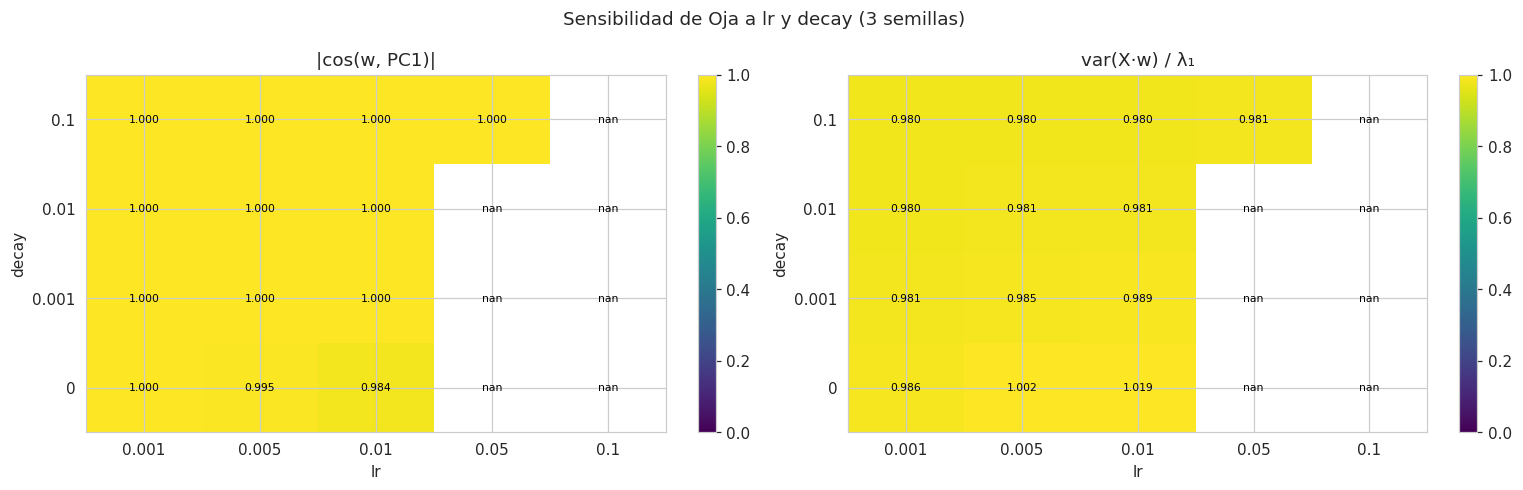


=== Vector final ===
|cos(w_mean, PC1)| = 1.0000


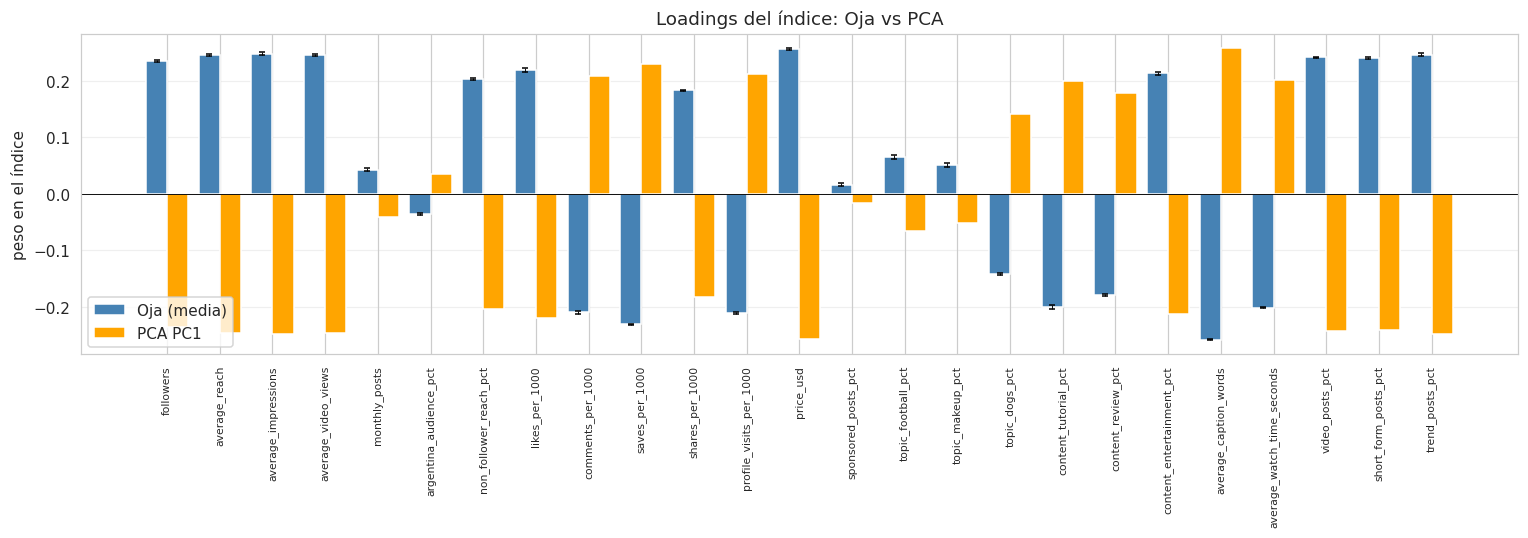


=== Comparación Oja vs PCA ===
  Pearson (scores):       +1.0000
  Spearman (rankings):    +0.9999
  MSE (scores):           0.0000
  Jaccard top-10 Oja/PCA: 1.000
  Jaccard top-10 Oja/Followers: 0.538


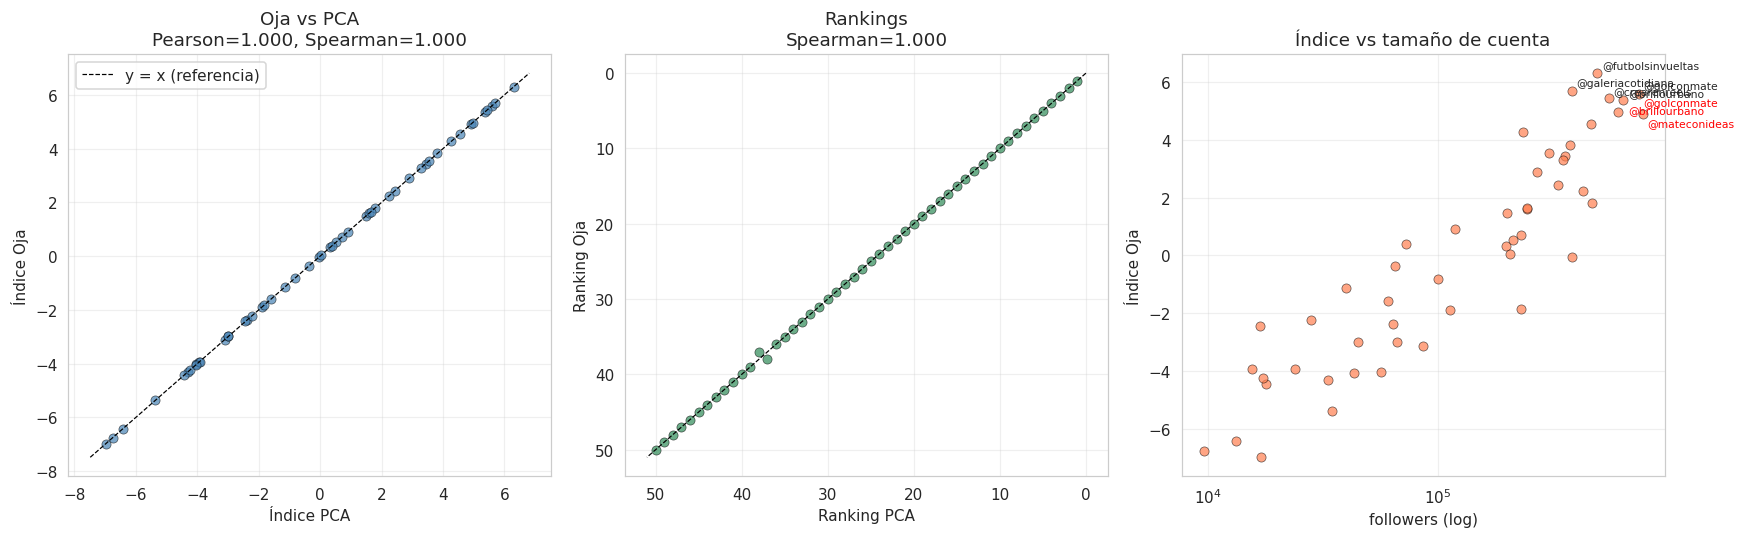


=== Top 10 por índice Oja ===
             name  followers  indice_oja  indice_pca
@futbolsinvueltas     493194    6.309672    6.307601
@galeriacotidiana     381324    5.700314    5.701346
      @golconmate     745025    5.600534    5.603590
    @crearenreels     551553    5.444157    5.446634
    @brillourbano     638718    5.368276    5.369635
  @maquillajereal     608003    4.966490    4.969198
    @mateconideas     775589    4.911079    4.908318
 @tribunacreativa     461892    4.545313    4.547113
  @makeupconsejos     234076    4.280159    4.278057
     @vidaperruna     374949    3.821294    3.817780

=== Bottom 10 por índice Oja ===
              name  followers  indice_oja  indice_pca
   @mundoanimal.ar      17062   -6.984102   -6.985455
  @consejoscaninos       9604   -6.750993   -6.749619
 @huellasyconsejos      13235   -6.414487   -6.412560
   @ideasconhuella      34822   -5.369956   -5.370064
    @reelargentino      18000   -4.439112   -4.436394
 @perrosfelices.ar      3333

In [ ]:
# ============================================================
# EJERCICIO 3: Regla de Oja
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.stats import pearsonr, spearmanr

plt.rcParams['figure.dpi'] = 110

# ------------------------------------------------------------
# 1. Cargar artefactos del Ej1
# ------------------------------------------------------------
if not os.path.exists('ej1_pca.pkl'):
    raise FileNotFoundError("Ejecutá primero el Ej1 para generar ej1_pca.pkl")

art = joblib.load('ej1_pca.pkl')
X_std        = art['X_std']              # (N, D)
features     = art['features']
pca          = art['pca']
pc1_ref      = pca.components_[0].copy() # (D,)
eigvals      = art['eigvals']
explained    = art['explained']
df_names     = art['df_names']
dominant_topic = art['dominant_topic']

data_path = None
for cand in ["datos/creadores.csv", "creadores.csv"]:
    if os.path.exists(cand):
        data_path = cand; break
if data_path is None:
    from google.colab import files
    up = files.upload(); data_path = list(up.keys())[0]
df = pd.read_csv(data_path)

N, D = X_std.shape
print(f"X_std: {N} x {D}")
print(f"PC1 explica {explained[0]:.2%} de la varianza")

# ------------------------------------------------------------
# 2. Oja pura (sin renormalización) con lr decay y monitoreo
# ------------------------------------------------------------
class OjaNeuron:
    """
    Regla de Oja pura:
        Δw = η(t) · y · (x − y·w),   y = wᵀx
    No se renormaliza w en cada paso (el término −y²w ya controla la norma).
    """
    def __init__(self, lr=0.005, epochs=5000, decay=0.001, seed=0,
                 record_every=50):
        self.lr = lr
        self.epochs = epochs
        self.decay = decay
        self.seed = seed
        self.record_every = record_every

    def fit(self, X):
        rng = np.random.default_rng(self.seed)
        n, d = X.shape
        self.w = rng.normal(0, 0.01, d)

        self.history_w = [self.w.copy()]
        self.history_epoch = [0]

        for epoch in range(self.epochs):
            eta = self.lr / (1.0 + self.decay * epoch)
            order = rng.permutation(n)
            for i in order:
                x = X[i]
                y = x @ self.w
                self.w += eta * y * (x - y * self.w)

            if (epoch + 1) % self.record_every == 0:
                self.history_w.append(self.w.copy())
                self.history_epoch.append(epoch + 1)

        return self   # interfaz consistente con Ej2

    def score(self, X):
        return X @ self.w

# ------------------------------------------------------------
# 3. Entrenamiento con múltiples semillas y diagnóstico
# ------------------------------------------------------------
LR, EPOCHS, DECAY = 0.005, 5000, 0.001
SEEDS = [0, 1, 2, 3, 4]

nets = []
for s in SEEDS:
    net = OjaNeuron(lr=LR, epochs=EPOCHS, decay=DECAY, seed=s).fit(X_std)
    nets.append(net)

# Diagnóstico de convergencia: ||w||, |cos(w, PC1)|, var(X·w) por época
hist_w = np.array([n.history_w for n in nets])          # (seeds, epochs_rec, D)
epochs_rec = np.array(nets[0].history_epoch)

norms = np.linalg.norm(hist_w, axis=2)                  # (seeds, epochs_rec)
cos_pc1 = np.abs(hist_w @ pc1_ref) / (norms + 1e-12)    # valor absoluto
var_w   = np.array([[np.var(X_std @ w) for w in n.history_w] for n in nets])

print("\n=== Convergencia al final del entrenamiento ===")
print(f"||w|| final:  {norms[:, -1].mean():.4f} +/- {norms[:, -1].std():.4f}")
print(f"|cos(w,PC1)|: {cos_pc1[:, -1].mean():.4f} +/- {cos_pc1[:, -1].std():.4f}")
print(f"var(X·w):     {var_w[:, -1].mean():.4f} +/- {var_w[:, -1].std():.4f}")
print(f"var PC1 (ref):{eigvals[0]:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for i, s in enumerate(SEEDS):
    axes[0].plot(epochs_rec, norms[i], alpha=0.7, label=f'seed {s}')
    axes[1].plot(epochs_rec, cos_pc1[i], alpha=0.7, label=f'seed {s}')
    axes[2].plot(epochs_rec, var_w[i], alpha=0.7, label=f'seed {s}')

axes[0].axhline(1.0, color='black', ls='--', lw=0.8, label='||w||=1')
axes[0].set_xlabel('época'); axes[0].set_ylabel('||w||')
axes[0].set_title('Norma de w (sin renormalizar)')
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

axes[1].axhline(1.0, color='black', ls='--', lw=0.8)
axes[1].set_xlabel('época'); axes[1].set_ylabel('|cos(w, PC1)|')
axes[1].set_title('Alineación con PC1')
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)

axes[2].axhline(eigvals[0], color='black', ls='--', lw=0.8,
                label=f'λ₁ PCA = {eigvals[0]:.3f}')
axes[2].set_xlabel('época'); axes[2].set_ylabel('var(X·w)')
axes[2].set_title('Varianza capturada')
axes[2].legend(fontsize=8); axes[2].grid(alpha=0.3)

plt.suptitle('Diagnóstico de convergencia — Oja pura con lr decay', fontsize=12)
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 4. Sensibilidad a lr y decay
# ------------------------------------------------------------
lrs    = [0.001, 0.005, 0.01, 0.05, 0.1]
decays = [0.0, 0.001, 0.01, 0.1]

print("\n=== Sensibilidad lr × decay (media de 3 semillas) ===")
print(f"{'lr':>7} {'decay':>7} {'|cos|':>8} {'var/w_varPC1':>14}")
sens_rows = []
for lr in lrs:
    for dc in decays:
        cos_list, ratio_list = [], []
        for s in range(3):
            n_ = OjaNeuron(lr=lr, epochs=EPOCHS, decay=dc, seed=s,
                           record_every=EPOCHS).fit(X_std)
            cos = abs(n_.w @ pc1_ref) / (np.linalg.norm(n_.w) + 1e-12)
            cos_list.append(cos)
            ratio_list.append(np.var(X_std @ n_.w) / eigvals[0])
        c_mean, r_mean = np.mean(cos_list), np.mean(ratio_list)
        sens_rows.append((lr, dc, c_mean, r_mean))
        print(f"{lr:>7.4f} {dc:>7.4f} {c_mean:>8.4f} {r_mean:>14.4f}")

sens = pd.DataFrame(sens_rows, columns=['lr','decay','cos','ratio'])
pivot_cos   = sens.pivot(index='decay', columns='lr', values='cos')
pivot_ratio = sens.pivot(index='decay', columns='lr', values='ratio')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, piv, name in [(axes[0], pivot_cos, '|cos(w, PC1)|'),
                      (axes[1], pivot_ratio, 'var(X·w) / λ₁')]:
    im = ax.imshow(piv.values, aspect='auto', origin='lower',
                   cmap='viridis', vmin=0, vmax=1)
    ax.set_xticks(range(len(piv.columns)))
    ax.set_xticklabels([f'{v:g}' for v in piv.columns])
    ax.set_yticks(range(len(piv.index)))
    ax.set_yticklabels([f'{v:g}' for v in piv.index])
    ax.set_xlabel('lr'); ax.set_ylabel('decay')
    ax.set_title(name)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            val = piv.values[i, j]
            ax.text(j, i, f'{val:.3f}', ha='center', va='center',
                    fontsize=7, color='white' if val < 0.6 else 'black')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.suptitle('Sensibilidad de Oja a lr y decay (3 semillas)', fontsize=12)
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 5. Índice de Oja: promedio de semillas y orientación explícita
# ------------------------------------------------------------
# Promedio de w sobre semillas (todas cercanas a PC1)
W_seeds = np.array([n.w for n in nets])          # (seeds, D)
# Alinear signos respecto de la primera semilla
for i in range(1, len(W_seeds)):
    if np.dot(W_seeds[i], W_seeds[0]) < 0:
        W_seeds[i] = -W_seeds[i]
w_mean = W_seeds.mean(axis=0)
w_mean = w_mean / np.linalg.norm(w_mean)         # solo para reportar
w_std  = W_seeds.std(axis=0)

# Orientación: queremos índice positivo = mayor alcance/escala.
# Usamos 'followers' como proxy (columna preprocesada en X_std).
if 'followers' in features:
    idx_foll = features.index('followers')
else:
    idx_foll = 0  # fallback

scores_raw = X_std @ w_mean
if np.corrcoef(scores_raw, X_std[:, idx_foll])[0, 1] < 0:
    w_mean = -w_mean
    scores_raw = -scores_raw
    print("\n[Orientación] Se invirtió el signo de w para que índice ↑ ⇒ alcance ↑")

# Índice final
df = df.copy()
df['indice_oja'] = scores_raw

# Scores PCA también orientados igual para comparación justa
scores_pca_raw = X_std @ pc1_ref
if np.corrcoef(scores_pca_raw, X_std[:, idx_foll])[0, 1] < 0:
    scores_pca_raw = -scores_pca_raw
df['indice_pca'] = scores_pca_raw

# Para ranking: usamos w_mean (índice final) y pc1_ref alineado
cos_final = abs(w_mean @ pc1_ref)
print(f"\n=== Vector final ===")
print(f"|cos(w_mean, PC1)| = {cos_final:.4f}")

# ------------------------------------------------------------
# 6. Loadings Oja vs PCA
# ------------------------------------------------------------
x = np.arange(D); width = 0.4
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(x - width/2, w_mean, width, label='Oja (media)', color='steelblue',
       yerr=w_std, capsize=2, error_kw={'lw': 0.6})
ax.bar(x + width/2, pc1_ref, width, label='PCA PC1', color='orange')
ax.axhline(0, color='black', lw=0.6)
ax.set_xticks(x)
ax.set_xticklabels(features, rotation=90, fontsize=7)
ax.set_ylabel('peso en el índice')
ax.set_title('Loadings del índice: Oja vs PCA')
ax.legend(); ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 7. Comparación cuantitativa Oja vs PCA
# ------------------------------------------------------------
s_oja = df['indice_oja'].values
s_pca = df['indice_pca'].values

pear = pearsonr(s_oja, s_pca)[0]
spear = spearmanr(s_oja, s_pca)[0]
mse = float(np.mean((s_oja - s_pca)**2))

# Top-10 overlap
top10_oja = set(df.nlargest(10, 'indice_oja').index)
top10_pca = set(df.nlargest(10, 'indice_pca').index)
top10_fol = set(df.nlargest(10, 'followers').index)
jac_op = len(top10_oja & top10_pca) / len(top10_oja | top10_pca)
jac_of = len(top10_oja & top10_fol) / len(top10_oja | top10_fol)

print("\n=== Comparación Oja vs PCA ===")
print(f"  Pearson (scores):       {pear:+.4f}")
print(f"  Spearman (rankings):    {spear:+.4f}")
print(f"  MSE (scores):           {mse:.4f}")
print(f"  Jaccard top-10 Oja/PCA: {jac_op:.3f}")
print(f"  Jaccard top-10 Oja/Followers: {jac_of:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].scatter(s_pca, s_oja, alpha=0.7, c='steelblue', edgecolors='black', lw=0.4)
# Línea identidad informativa, pero reportamos la correlación
lim = [min(s_pca.min(), s_oja.min()) - 0.5, max(s_pca.max(), s_oja.max()) + 0.5]
axes[0].plot(lim, lim, 'k--', lw=0.8, label='y = x (referencia)')
axes[0].set_xlabel('Índice PCA'); axes[0].set_ylabel('Índice Oja')
axes[0].set_title(f'Oja vs PCA\nPearson={pear:.3f}, Spearman={spear:.3f}')
axes[0].legend(); axes[0].grid(alpha=0.3)

# Ranking comparado
rank_oja = df['indice_oja'].rank(ascending=False)
rank_pca = df['indice_pca'].rank(ascending=False)
axes[1].scatter(rank_pca, rank_oja, alpha=0.7, c='seagreen', edgecolors='black', lw=0.4)
axes[1].plot([0, N+1], [0, N+1], 'k--', lw=0.8)
axes[1].set_xlabel('Ranking PCA'); axes[1].set_ylabel('Ranking Oja')
axes[1].set_title(f'Rankings\nSpearman={spear:.3f}')
axes[1].invert_xaxis(); axes[1].invert_yaxis()
axes[1].grid(alpha=0.3)

# Followers vs índice
axes[2].scatter(df['followers'], df['indice_oja'], alpha=0.7,
                c='coral', edgecolors='black', lw=0.4)
for i in df.nlargest(5, 'indice_oja').index:
    axes[2].annotate(df['name'].iloc[i],
                     (df['followers'].iloc[i], df['indice_oja'].iloc[i]),
                     fontsize=7, xytext=(3,3), textcoords='offset points')
for i in df.nlargest(3, 'followers').index:
    axes[2].annotate(df['name'].iloc[i],
                     (df['followers'].iloc[i], df['indice_oja'].iloc[i]),
                     fontsize=7, xytext=(3,-8), textcoords='offset points',
                     color='red')
axes[2].set_xscale('log')
axes[2].set_xlabel('followers (log)'); axes[2].set_ylabel('Índice Oja')
axes[2].set_title('Índice vs tamaño de cuenta')
axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 8. Rankings
# ------------------------------------------------------------
print("\n=== Top 10 por índice Oja ===")
cols = ['name', 'followers', 'indice_oja', 'indice_pca']
print(df.nlargest(10, 'indice_oja')[cols].to_string(index=False))

print("\n=== Bottom 10 por índice Oja ===")
print(df.nsmallest(10, 'indice_oja')[cols].to_string(index=False))

print("\n=== Top 10 por followers ===")
print(df.nlargest(10, 'followers')[cols].to_string(index=False))

print("\n=== Top 10 por PC1 (PCA) ===")
print(df.nlargest(10, 'indice_pca')[cols].to_string(index=False))

# ------------------------------------------------------------
# 9. Guardar para el Ej4
# ------------------------------------------------------------
joblib.dump({
    'w_oja_mean': w_mean,
    'w_oja_std':  w_std,
    'cos_pc1':    cos_final,
    'indice_oja': df['indice_oja'].values,
    'indice_pca': df['indice_pca'].values,
    'pearson':    pear,
    'spearman':   spear,
    'jaccard_top10_oja_pca': jac_op,
    'jaccard_top10_oja_fol': jac_of,
}, 'ej3_oja.pkl')
print("\nResultados guardados en ej3_oja.pkl")

Creadores: 50, clusters activos: 36

=== Futbol — Marca de ropa de entrenamiento para fútbol (objetivo: ventas) ===
                name  followers  average_reach  non_follower_reach_pct  content_tutorial_pct  profile_visits_per_1000  price_usd  argentina_audience_pct cluster  score_Futbol
20       @golconmate     745025         268518                   59.70                 12.94                    10.69    3251.20                   77.46   (5,5)          0.70
8     @futbolcononda     198136          89301                   76.41                 32.33                    16.76    1457.34                   89.37   (5,1)          0.62
4   @tribunacreativa     461892         178805                   82.10                  8.25                    11.92    2806.20                   68.30   (4,4)          0.57
26  @pasionalbirroja      17481           8758                   61.82                 40.91                    19.95     238.58                   40.29   (4,0)          0.56
29     @l

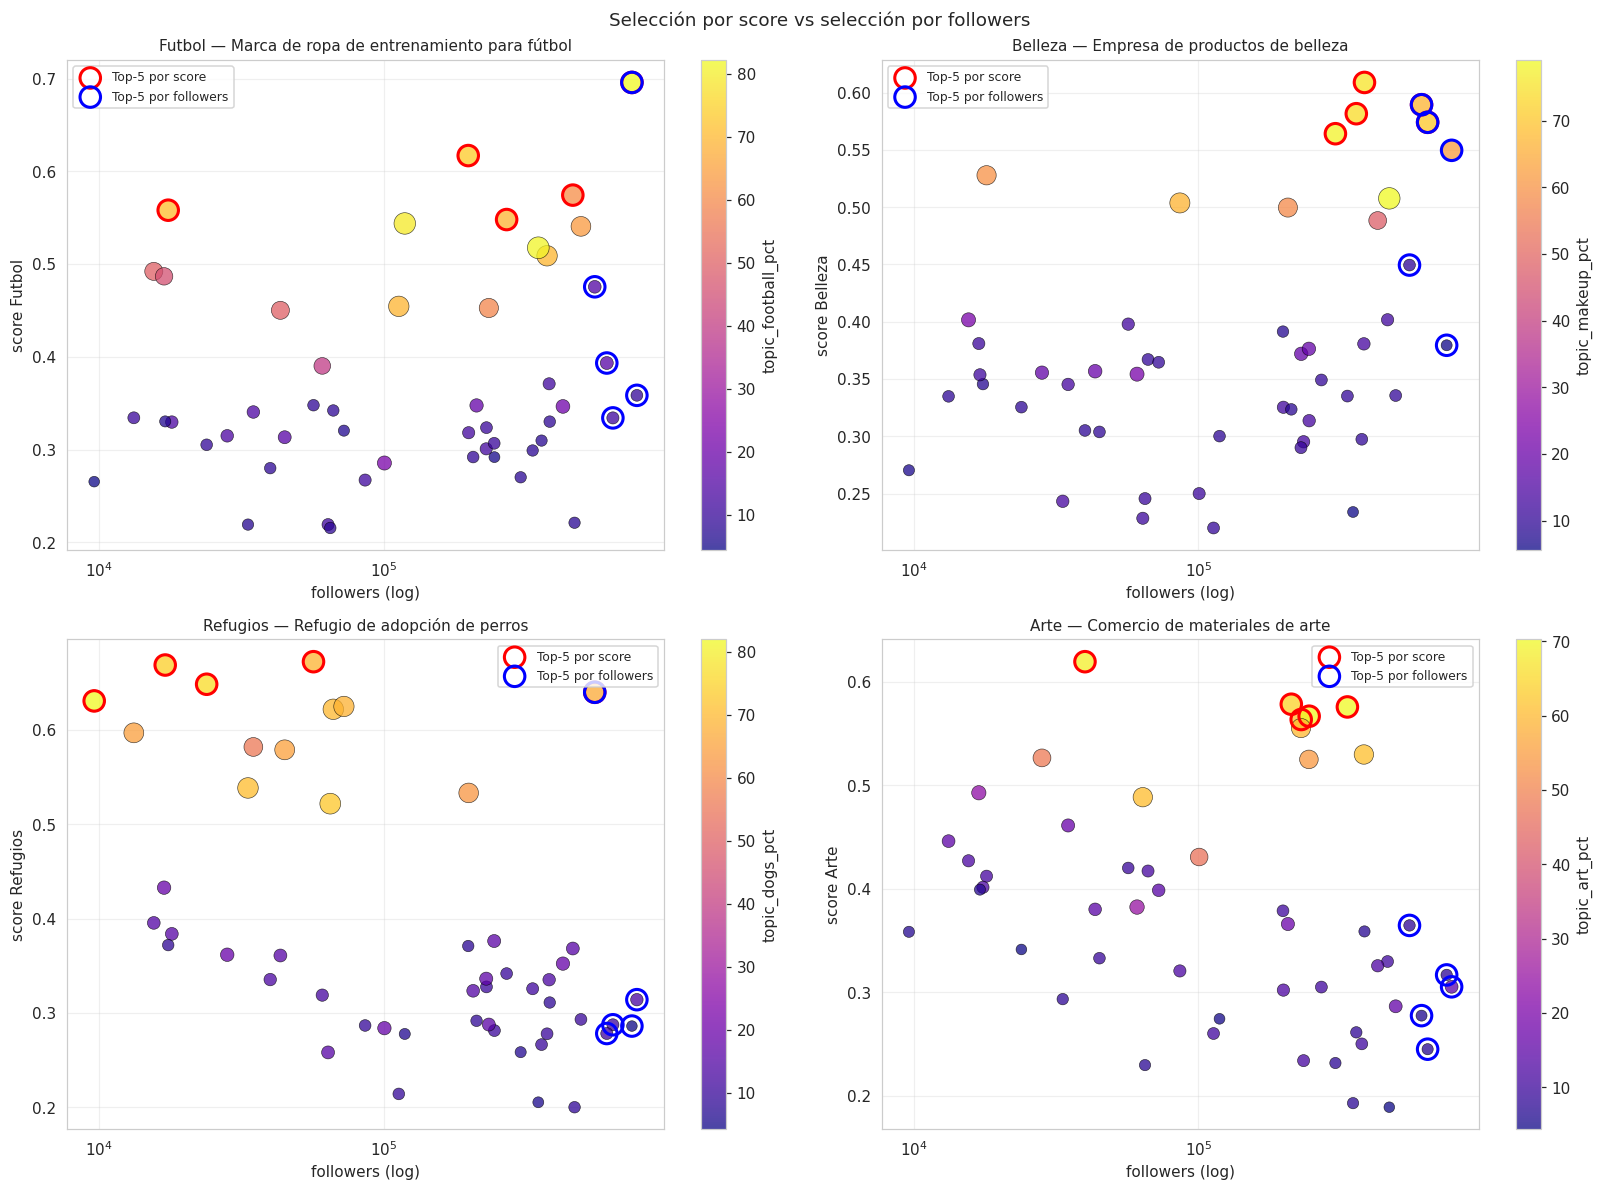

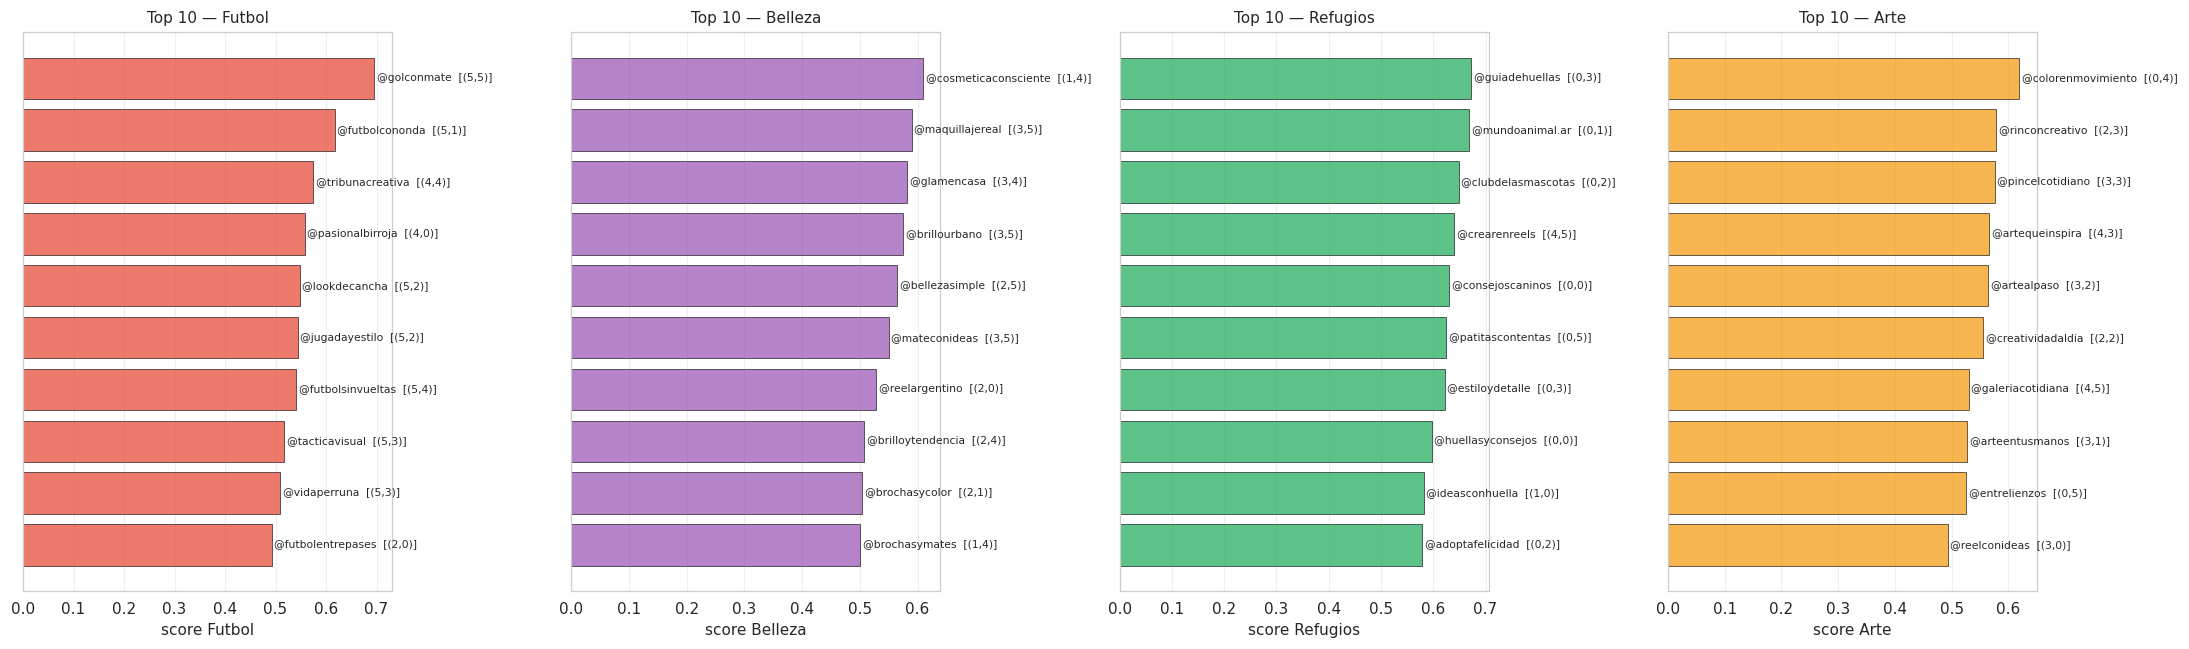

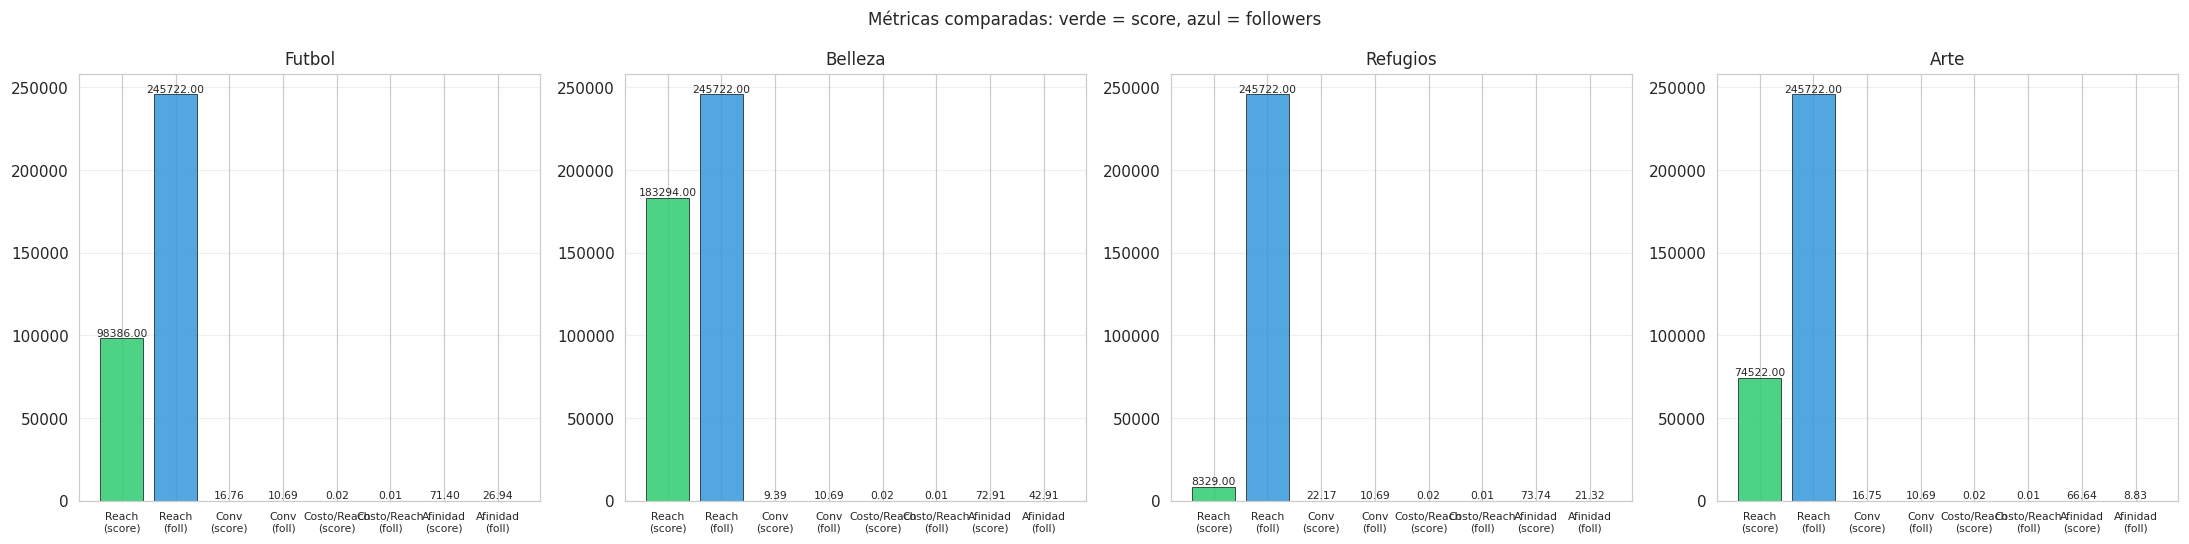

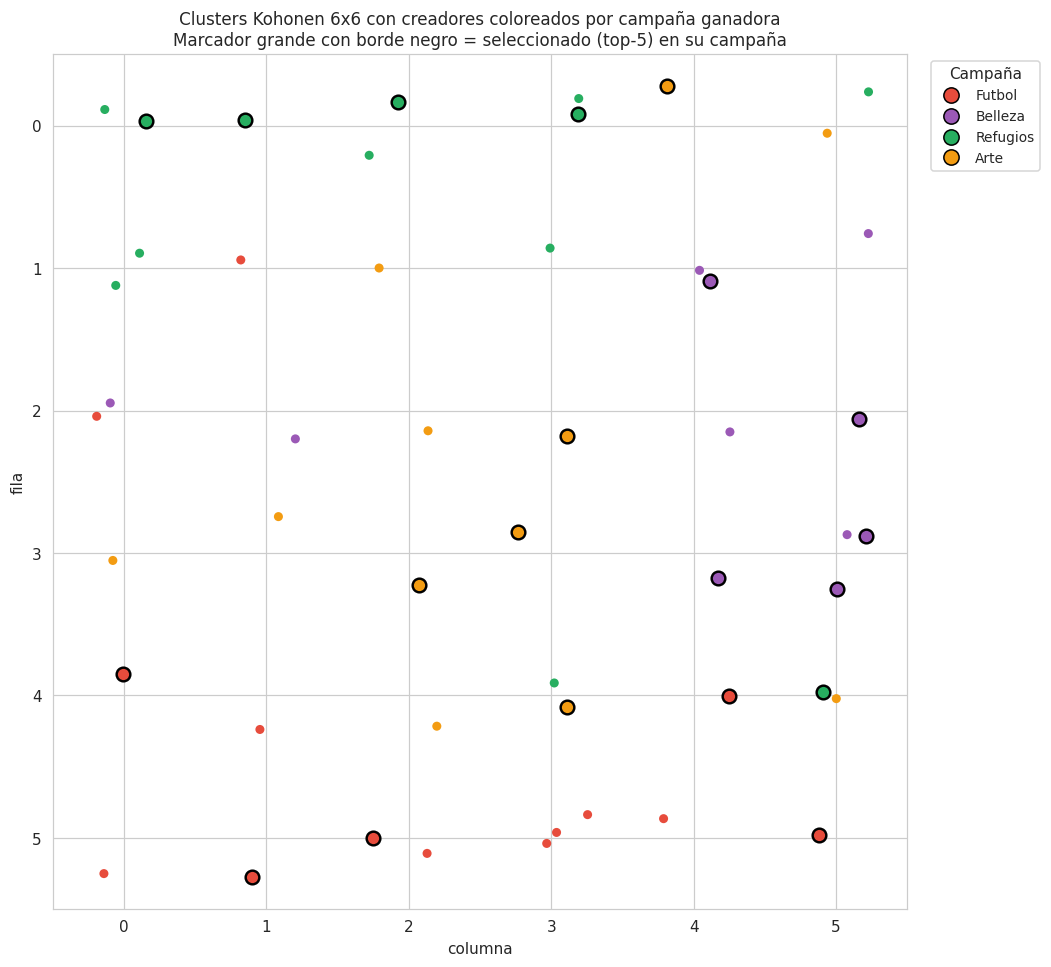


Resultados guardados en ej4_campanas.pkl


In [ ]:
# ============================================================
# EJERCICIO 4: Decisión para las campañas
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from matplotlib.lines import Line2D

plt.rcParams['figure.dpi'] = 110

# ------------------------------------------------------------
# 1. Cargar artefactos de Ej1, Ej2, Ej3 (trazabilidad)
# ------------------------------------------------------------
for f in ['ej1_pca.pkl', 'ej2_kohonen.pkl', 'ej3_oja.pkl']:
    if not os.path.exists(f):
        raise FileNotFoundError(f"Falta {f}. Ejecutá Ej1, Ej2 y Ej3 primero.")

art1 = joblib.load('ej1_pca.pkl')
art2 = joblib.load('ej2_kohonen.pkl')
art3 = joblib.load('ej3_oja.pkl')

features     = art1['features']
X_std        = art1['X_std']
pcs          = art1['pcs']
df_names     = art1['df_names']

labels       = art2['labels']          # (N,2) BMU por creador
K            = art2['k']
net_W        = art2['net_W']

w_oja        = art3['w_oja_mean']      # ya orientado: alto => mayor alcance
indice_oja   = art3['indice_oja']
indice_pca   = art3['indice_pca']

# Dataframe original
data_path = None
for cand in ["datos/creadores.csv", "creadores.csv"]:
    if os.path.exists(cand):
        data_path = cand; break
if data_path is None:
    from google.colab import files
    up = files.upload(); data_path = list(up.keys())[0]
df = pd.read_csv(data_path)

N = len(df)
assert N == len(labels) == len(indice_oja), "Longitudes inconsistentes"

# Reconstrucción de variables descartadas como features pero útiles como métricas
df['total_engagement_per_1000'] = (
    df['likes_per_1000'] + df['comments_per_1000'] +
    df['saves_per_1000'] + df['shares_per_1000'])
df['estimated_argentina_reach'] = df['average_reach'] * df['argentina_audience_pct'] / 100

df['cluster']    = [f"({i},{j})" for i, j in labels]
df['indice_oja'] = indice_oja
df['indice_pca'] = indice_pca

# Métricas de costo-eficiencia
df['reach_por_usd']     = df['average_reach'] / df['price_usd']
df['reach_arg_por_usd'] = df['estimated_argentina_reach'] / df['price_usd']

print(f"Creadores: {N}, clusters activos: {len(df['cluster'].unique())}")

# ------------------------------------------------------------
# 2. Componentes de decisión normalizados (0-1)
# ------------------------------------------------------------
def norm01(s):
    return (s - s.min()) / (s.max() - s.min() + 1e-12)

comp = pd.DataFrame(index=df.index)

# Afinidad temática
comp['topic_football'] = norm01(df['topic_football_pct'])
comp['topic_makeup']   = norm01(df['topic_makeup_pct'])
comp['topic_dogs']     = norm01(df['topic_dogs_pct'])
comp['topic_art']      = norm01(df['topic_art_pct'])

# Objetivos operacionalizados
comp['alcance_masivo']  = norm01(df['average_reach'])
comp['descubrimiento']  = norm01(df['non_follower_reach_pct'])
comp['profundidad_edu'] = norm01(0.5 * df['content_tutorial_pct'] +
                                 0.3 * df['average_watch_time_seconds'] +
                                 0.2 * df['average_caption_words'])
comp['conversion']      = norm01(0.5 * df['profile_visits_per_1000'] +
                                 0.3 * df['comments_per_1000'] +
                                 0.2 * df['saves_per_1000'])

# Costo-eficiencia y relevancia local
comp['costo_eficiencia'] = norm01(df['reach_por_usd'])
comp['arg_relevancia']   = norm01(df['estimated_argentina_reach'])
comp['indice_oja_pos']   = norm01(df['indice_oja'])   # ya positivo = mayor alcance

# ------------------------------------------------------------
# 3. Campañas: cliente, objetivo y pesos específicos
# ------------------------------------------------------------
campañas = {
    'Futbol': {
        'topic':   'topic_football',
        'cliente': 'Marca de ropa de entrenamiento para fútbol',
        'objetivo':'ventas',
        'pesos': {
            'topic_football': 0.30,
            'alcance_masivo': 0.15,
            'descubrimiento': 0.10,
            'profundidad_edu':0.10,
            'conversion':     0.20,
            'costo_eficiencia':0.10,
            'arg_relevancia': 0.05,
        }
    },
    'Belleza': {
        'topic':   'topic_makeup',
        'cliente': 'Empresa de productos de belleza',
        'objetivo':'ventas',
        'pesos': {
            'topic_makeup':   0.30,
            'alcance_masivo': 0.10,
            'descubrimiento': 0.15,
            'profundidad_edu':0.10,
            'conversion':     0.20,
            'costo_eficiencia':0.10,
            'arg_relevancia': 0.05,
        }
    },
    'Refugios': {
        'topic':   'topic_dogs',
        'cliente': 'Refugio de adopción de perros',
        'objetivo':'consultas y adopciones',
        'pesos': {
            'topic_dogs':     0.35,
            'alcance_masivo': 0.05,
            'descubrimiento': 0.15,
            'profundidad_edu':0.10,
            'conversion':     0.25,
            'costo_eficiencia':0.05,
            'arg_relevancia': 0.05,
        }
    },
    'Arte': {
        'topic':   'topic_art',
        'cliente': 'Comercio de materiales de arte',
        'objetivo':'ventas',
        'pesos': {
            'topic_art':      0.30,
            'alcance_masivo': 0.05,
            'descubrimiento': 0.10,
            'profundidad_edu':0.20,
            'conversion':     0.20,
            'costo_eficiencia':0.10,
            'arg_relevancia': 0.05,
        }
    }
}

for name, cfg in campañas.items():
    s = sum(cfg['pesos'].values())
    assert abs(s - 1.0) < 1e-6, f"Pesos de {name} suman {s}"

# ------------------------------------------------------------
# 4. Score por campaña y top-k
# ------------------------------------------------------------
TOP_K = 5
selecciones = {}
for name, cfg in campañas.items():
    score = sum(comp[k] * w for k, w in cfg['pesos'].items())
    df[f'score_{name}'] = score
    topk = df.nlargest(TOP_K, f'score_{name}').index
    selecciones[name] = topk

    print(f"\n=== {name} — {cfg['cliente']} (objetivo: {cfg['objetivo']}) ===")
    print(df.loc[topk, ['name','followers','average_reach',
                        'non_follower_reach_pct','content_tutorial_pct',
                        'profile_visits_per_1000','price_usd',
                        'argentina_audience_pct','cluster',
                        f'score_{name}']].round(2).to_string())

# ------------------------------------------------------------
# 5. Comparación contra estrategia basada solo en followers
# ------------------------------------------------------------
topk_followers = df.nlargest(TOP_K, 'followers').index

def metrics(idxs):
    return {
        'reach':            df.loc[idxs, 'average_reach'].median(),
        'non_follower':     df.loc[idxs, 'non_follower_reach_pct'].median(),
        'engagement':       df.loc[idxs, 'total_engagement_per_1000'].median(),
        'conv':             df.loc[idxs, 'profile_visits_per_1000'].median(),
        'price':            df.loc[idxs, 'price_usd'].median(),
        'arg_reach':        df.loc[idxs, 'estimated_argentina_reach'].median(),
        'cost_reach':       (df.loc[idxs, 'price_usd'] /
                             df.loc[idxs, 'average_reach']).median(),
        'cost_arg_reach':   (df.loc[idxs, 'price_usd'] /
                             df.loc[idxs, 'estimated_argentina_reach']).median(),
    }

rows = []
for name in campañas:
    idxs_score = selecciones[name]
    m_score = metrics(idxs_score)
    m_foll  = metrics(topk_followers)

    topic_col = campañas[name]['topic'] + '_pct'
    aff_score = df.loc[idxs_score, topic_col].mean()
    aff_foll  = df.loc[topk_followers, topic_col].mean()

    # Solapamiento entre las dos selecciones
    overlap = len(set(idxs_score) & set(topk_followers))

    rows.append({
        'Campaña': name,
        'Reach_score': m_score['reach'],   'Reach_foll': m_foll['reach'],
        'Non_foll_score': m_score['non_follower'], 'Non_foll_foll': m_foll['non_follower'],
        'Conv_score': m_score['conv'],     'Conv_foll': m_foll['conv'],
        'Costo/Reach_score': m_score['cost_reach'],
        'Costo/Reach_foll':  m_foll['cost_reach'],
        'Arg_reach_score': m_score['arg_reach'],
        'Arg_reach_foll':  m_foll['arg_reach'],
        'Afinidad_topic_score': aff_score,
        'Afinidad_topic_foll':  aff_foll,
        'Solapamiento': overlap,
    })

comp_df = pd.DataFrame(rows).round(2)
print("\n=== Comparación: selección por score vs selección por followers ===")
print(comp_df.to_string(index=False))

# ------------------------------------------------------------
# 6. Visualizaciones
# ------------------------------------------------------------
palette = {'Futbol': '#e74c3c', 'Belleza': '#9b59b6',
           'Refugios': '#27ae60', 'Arte': '#f39c12'}

# 6.1 Scatter followers (log) vs score, coloreado por afinidad temática
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()
for ax, (name, cfg) in zip(axes, campañas.items()):
    topic_col = cfg['topic'] + '_pct'
    scatter = ax.scatter(df['followers'], df[f'score_{name}'],
                          c=df[topic_col], cmap='plasma',
                          s=40 + 200 * (df[topic_col] / 100),
                          alpha=0.75, edgecolors='black', linewidth=0.4)
    plt.colorbar(scatter, ax=ax, label=topic_col)

    ax.scatter(df.loc[selecciones[name], 'followers'],
               df.loc[selecciones[name], f'score_{name}'],
               s=180, facecolors='none', edgecolors='red', linewidth=2,
               label=f'Top-{TOP_K} por score')
    ax.scatter(df.loc[topk_followers, 'followers'],
               df.loc[topk_followers, f'score_{name}'],
               s=180, facecolors='none', edgecolors='blue', linewidth=2,
               label=f'Top-{TOP_K} por followers')

    ax.set_xscale('log')
    ax.set_xlabel('followers (log)')
    ax.set_ylabel(f'score {name}')
    ax.set_title(f'{name} — {cfg["cliente"]}', fontsize=10)
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.suptitle('Selección por score vs selección por followers', fontsize=12)
plt.tight_layout(); plt.show()

# 6.2 Ranking top-10 por score
fig, axes = plt.subplots(1, 4, figsize=(20, 6))
for ax, (name, cfg) in zip(axes, campañas.items()):
    top10 = df.nlargest(10, f'score_{name}')
    y = np.arange(len(top10))[::-1]
    ax.barh(y, top10[f'score_{name}'], color=palette[name],
            alpha=0.75, edgecolor='black', linewidth=0.5)
    for yi, (_, row) in zip(y, top10.iterrows()):
        ax.text(row[f'score_{name}'] + 0.005, yi,
                f"{row['name']}  [{row['cluster']}]",
                va='center', fontsize=7)
    ax.set_yticks([]); ax.set_xlabel(f'score {name}')
    ax.set_title(f'Top 10 — {name}', fontsize=10)
    ax.grid(alpha=0.3, axis='x')
plt.tight_layout(); plt.show()

# 6.3 Comparación cuantitativa por campaña
metrics_to_plot = ['Reach_score', 'Reach_foll',
                   'Conv_score', 'Conv_foll',
                   'Costo/Reach_score', 'Costo/Reach_foll',
                   'Afinidad_topic_score', 'Afinidad_topic_foll']
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, name in zip(axes, campañas):
    row = comp_df[comp_df['Campaña'] == name].iloc[0]
    labels_ = ['Reach\n(score)', 'Reach\n(foll)', 'Conv\n(score)', 'Conv\n(foll)',
               'Costo/Reach\n(score)', 'Costo/Reach\n(foll)',
               'Afinidad\n(score)', 'Afinidad\n(foll)']
    vals = [row[k] for k in metrics_to_plot]
    colors = ['#2ecc71' if i % 2 == 0 else '#3498db' for i in range(len(vals))]
    bars = ax.bar(labels_, vals, color=colors, alpha=0.85,
                  edgecolor='black', linewidth=0.5)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v, f'{v:.2f}',
                ha='center', va='bottom', fontsize=7)
    ax.set_title(name, fontsize=11)
    ax.tick_params(axis='x', labelsize=7, rotation=0)
    ax.grid(alpha=0.3, axis='y')
plt.suptitle('Métricas comparadas: verde = score, azul = followers', fontsize=11)
plt.tight_layout(); plt.show()

# 6.4 Mapa de clusters de Kohonen con selección de cada campaña superpuesta
fig, ax = plt.subplots(figsize=(max(8, K*1.6), max(8, K*1.6)))
ax.set_xlim(-0.5, K-0.5); ax.set_ylim(-0.5, K-0.5)
ax.set_aspect('equal'); ax.invert_yaxis()

# Neuronas muertas
for i in range(K):
    for j in range(K):
        if art2['dead_mask'][i, j]:
            ax.add_patch(plt.Rectangle((j-0.5, i-0.5), 1, 1,
                                       facecolor='#eaeaea', edgecolor='gray',
                                       linewidth=0.8, hatch='//', alpha=0.7))

# Creadores marcados por campaña ganadora (argmax entre los 4 scores)
score_cols = [f'score_{n}' for n in campañas]
df['campaign_winner'] = df[score_cols].idxmax(axis=1).str.replace('score_', '')
for idx_row, row in df.iterrows():
    i, j = labels[idx_row]
    # pequeño jitter para no superponer
    rng = np.random.default_rng(idx_row)
    dx, dy = rng.uniform(-0.28, 0.28, 2)
    color = palette[row['campaign_winner']]
    is_selected = any(idx_row in selecciones[c] for c in campañas)
    ax.scatter(j + dx, i + dy, s=80 if is_selected else 35,
               c=color, edgecolors='black' if is_selected else 'none',
               linewidth=1.6 if is_selected else 0.3, zorder=5)

ax.set_xticks(range(K)); ax.set_yticks(range(K))
ax.set_xlabel('columna'); ax.set_ylabel('fila')
ax.set_title(f'Clusters Kohonen {K}x{K} con creadores coloreados por campaña ganadora\n'
             f'Marcador grande con borde negro = seleccionado (top-{TOP_K}) en su campaña',
             fontsize=11)
legend_handles = [Line2D([0],[0], marker='o', color='w',
                          markerfacecolor=palette[n], markersize=10,
                          markeredgecolor='black', label=n) for n in campañas]
ax.legend(handles=legend_handles, title='Campaña',
          loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 7. Persistencia
# ------------------------------------------------------------
joblib.dump({
    'comp': comp,
    'campañas': campañas,
    'selecciones': {n: list(idxs) for n, idxs in selecciones.items()},
    'topk_followers': list(topk_followers),
    'comparacion': comp_df,
    'scores_cols': [f'score_{n}' for n in campañas],
}, 'ej4_campanas.pkl')
print("\nResultados guardados en ej4_campanas.pkl")

Subí las 5 imágenes QR (nombres: Food_menu.png, Wine_menu.png, Beverages_menu.png, Dessert_menu.png, Specials_menu.png)


Saving beverages_menu_qr.png to beverages_menu_qr.png
Saving dessert_menu_qr.png to dessert_menu_qr.png
Saving food_menu_qr.png to food_menu_qr (1).png
Saving specials_menu_qr.png to specials_menu_qr (1).png
Saving wine_menu_qr.png to wine_menu_qr (1).png

Imágenes asignadas:
  Food       -> uploaded
  Wine       -> uploaded
  Beverages  -> uploaded
  Dessert    -> uploaded
  Specials   -> uploaded
Food: shape=(37, 37), proporción +1 = 0.519
Wine: shape=(37, 37), proporción +1 = 0.516
Beverages: shape=(37, 37), proporción +1 = 0.519
Dessert: shape=(37, 37), proporción +1 = 0.526
Specials: shape=(37, 37), proporción +1 = 0.514

M = 5 patrones, N = 1369 neuronas, ratio M/N = 0.0037

=== Matriz de solapamiento (producto interno / N) ===
            Food   Wine  Beverages  Dessert  Specials
Food       1.000  0.860      0.600    0.594     0.766
Wine       0.860  1.000      0.576    0.576     0.763
Beverages  0.600  0.576      1.000    0.757     0.594
Dessert    0.594  0.576      0.757    1.

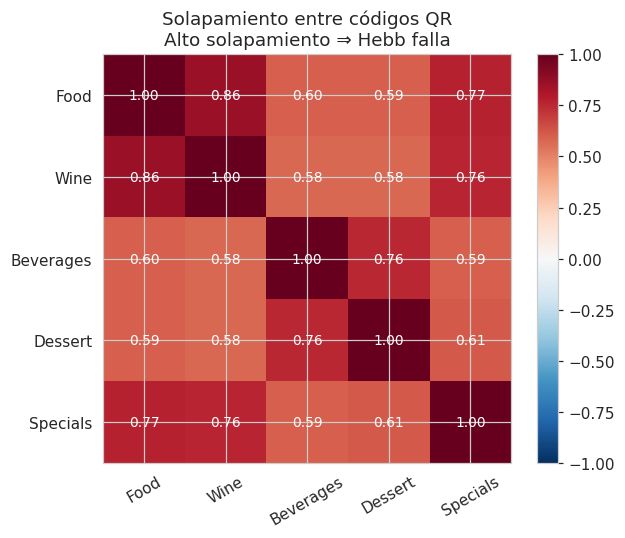


=== Verificación de punto fijo (ruido = 0, async) ===
Patrón        Hebb eq?    PInv eq?   Hebb dif   PInv dif
Food             False        True         71          0
Wine             False        True         91          0
Beverages        False        True        225          0
Dessert          False        True        225          0
Specials         False        True        103          0

=== Robustez al ruido (async) ===

--- Red: Hebb ---
Exact recovery rate:
ruido      0.00  0.02  0.05  0.10  0.15  0.20  0.30  0.40
patrón                                                   
Beverages   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
Dessert     0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
Food        0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
Specials    0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
Wine        0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0

Correct menu identification rate:
ruido      0.00  0.02  0.05  0.10  0.15  0.20  0.30  0.40
patrón                       

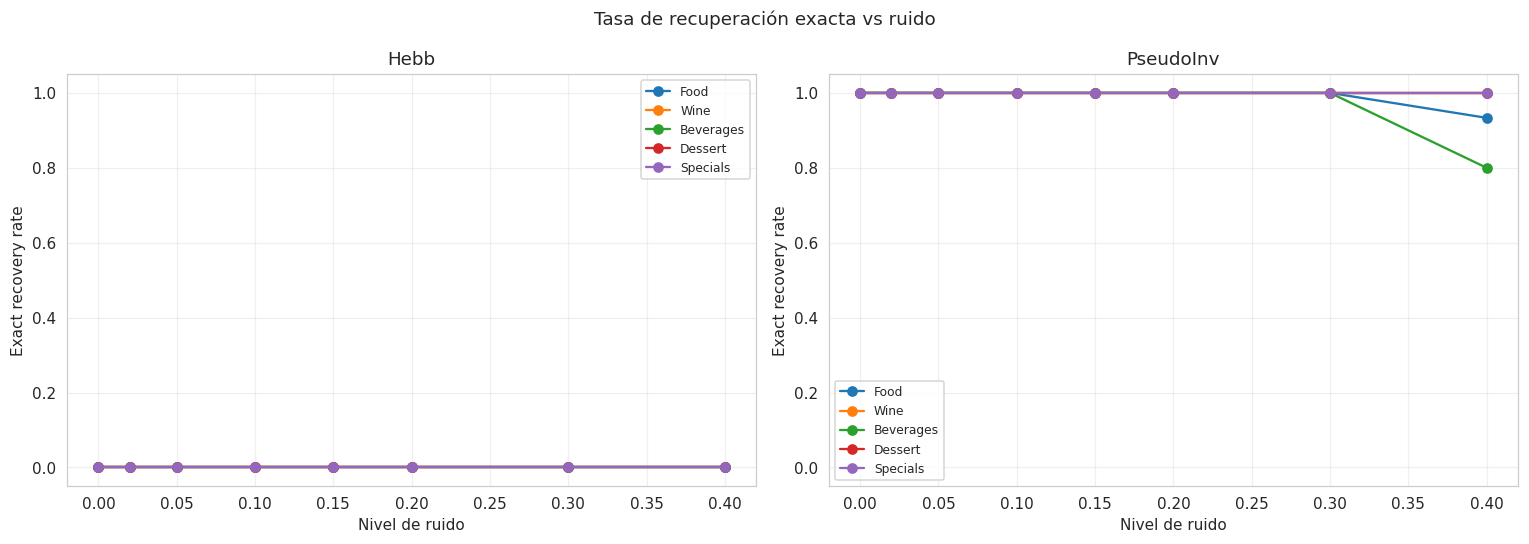


=== Energía de los patrones almacenados ===
Hebb      : Food=-2077.4, Wine=-2041.5, Beverages=-1789.7, Dessert=-1801.8, Specials=-1982.5
PseudoInv : Food=-684.5, Wine=-684.5, Beverages=-684.5, Dessert=-684.5, Specials=-684.5

Energía del estado mezcla uniforme:
  Hebb: -2172.9
  PseudoInv: -610.4


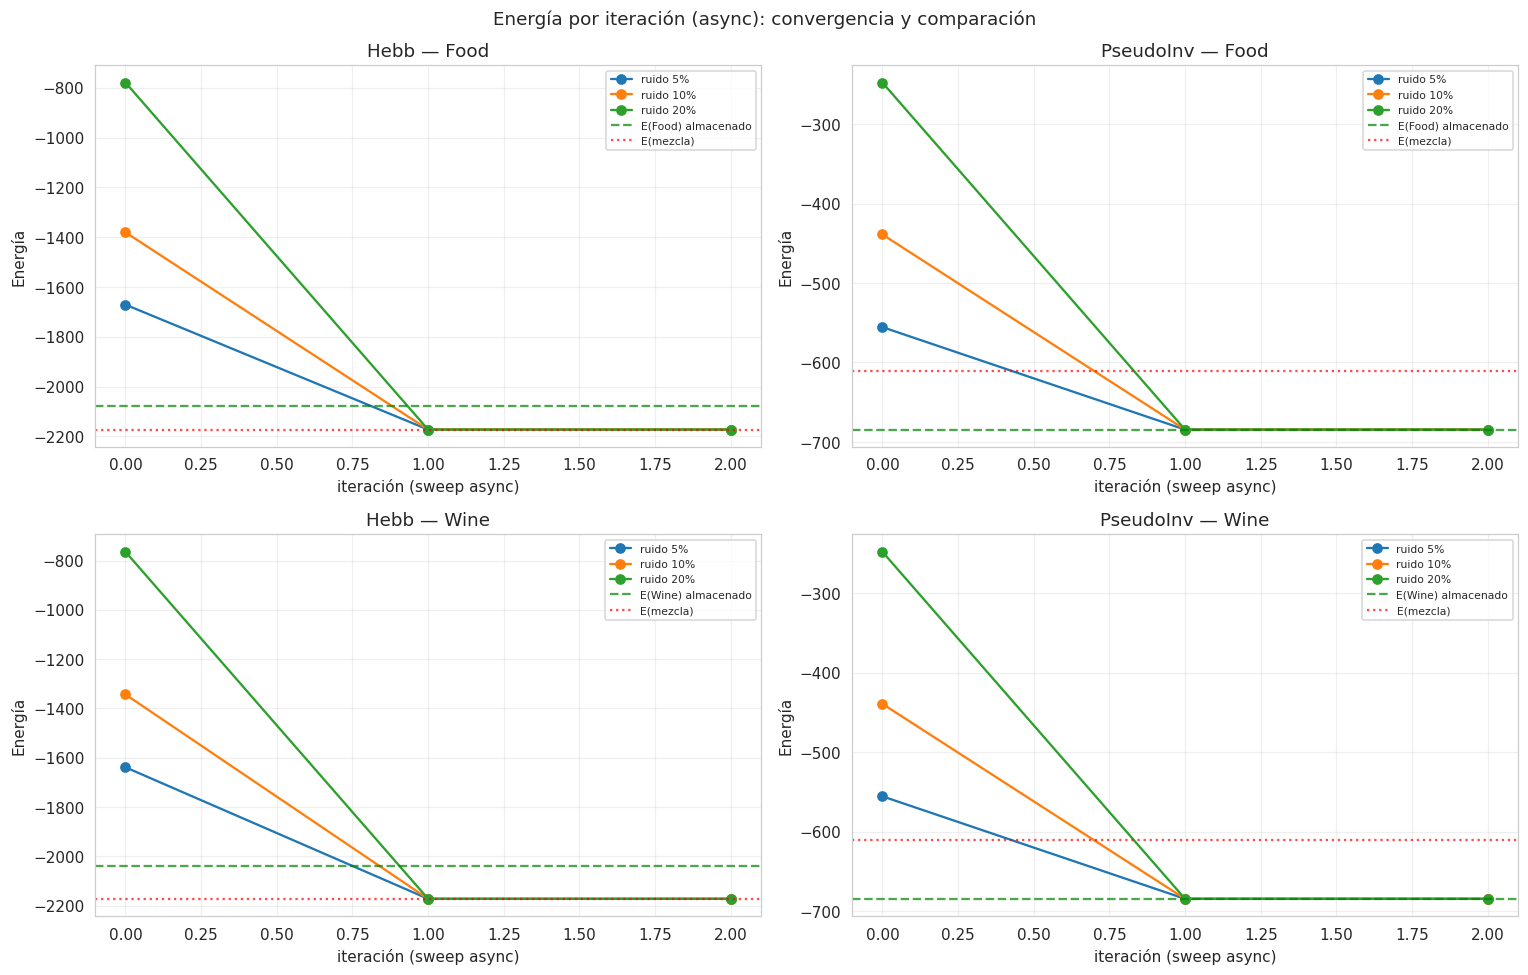


=== Visualización para red Hebb — ruido 10% ===


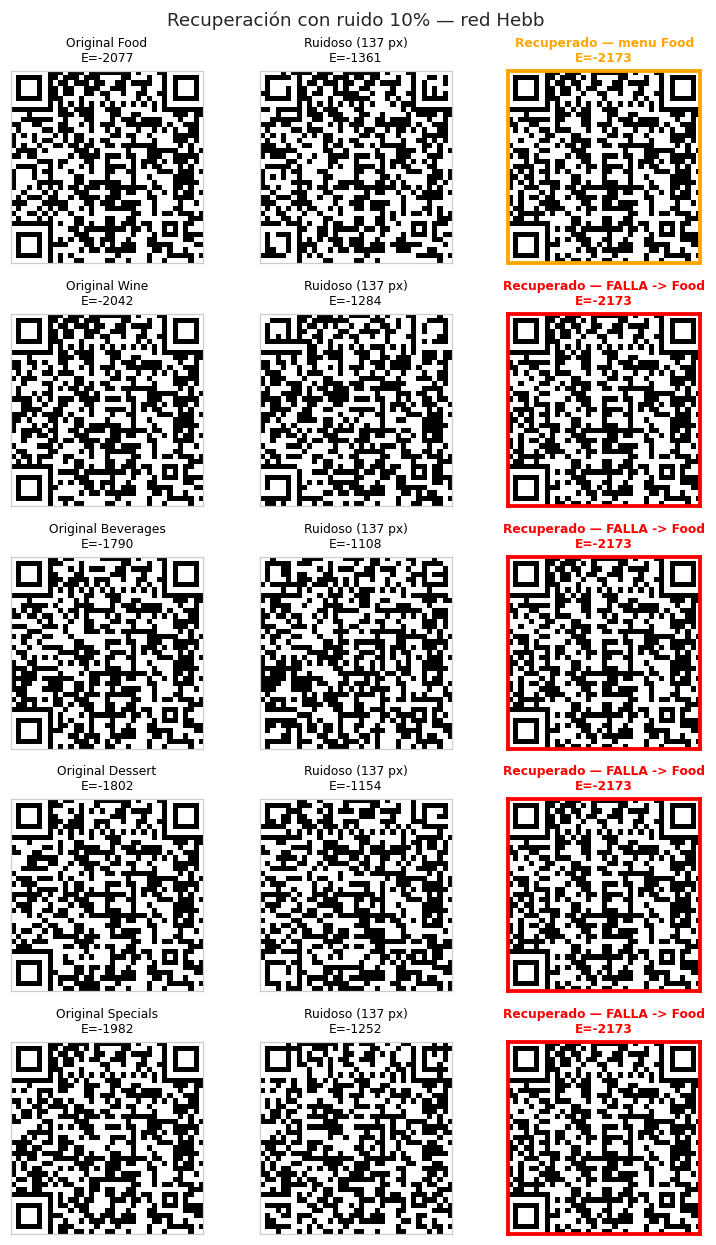


=== Visualización para red PseudoInv — ruido 10% ===


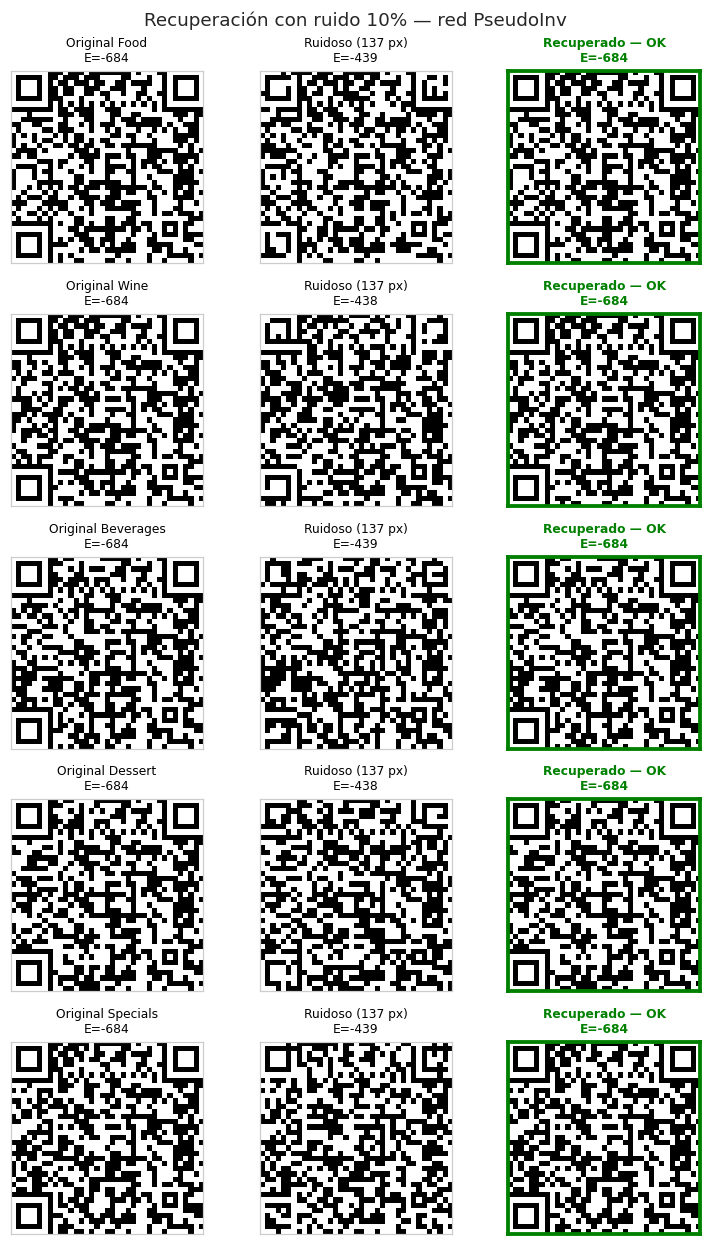


=== Iteraciones hasta convergencia (media) ===
red       Hebb                PseudoInv               
ruido     0.00 0.05 0.10 0.20      0.00 0.05 0.10 0.20
patrón                                                
Beverages  2.0  2.3  2.5  2.2       1.0  2.0  2.0  2.0
Dessert    2.0  2.1  2.0  2.3       1.0  2.0  2.0  2.0
Food       2.0  2.0  2.0  2.0       1.0  2.0  2.0  2.0
Specials   2.0  2.0  2.0  2.0       1.0  2.0  2.0  2.0
Wine       2.0  2.0  2.0  2.0       1.0  2.0  2.0  2.0

Artefactos guardados en ej5_hopfield_qr.pkl


In [ ]:
# ============================================================
# EJERCICIO 5: Hopfield con códigos QR
# ============================================================
import os
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

plt.rcParams['figure.dpi'] = 110

# ------------------------------------------------------------
# 1. Carga de imágenes
# ------------------------------------------------------------
NOMBRES_ESPERADOS = ['Food', 'Wine', 'Beverages', 'Dessert', 'Specials']
KEYWORDS = {
    'Food':      ['food', 'menu_food'],
    'Wine':      ['wine', 'vino'],
    'Beverages': ['beverage', 'drink', 'bebida'],
    'Dessert':   ['dessert', 'postre'],
    'Specials':  ['special', 'especial'],
}

def cargar_imagenes():
    """Busca datos/hopfield/; si no existe, pide upload con confirmación explícita."""
    rutas = {}
    # Buscar carpeta
    for folder in ['datos/hopfield', 'hopfield', 'qr', '.']:
        if os.path.isdir(folder):
            for f in os.listdir(folder):
                low = f.lower()
                if not low.endswith(('.png', '.jpg', '.jpeg')):
                    continue
                for nombre, kws in KEYWORDS.items():
                    if any(k in low for k in kws):
                        rutas[nombre] = os.path.join(folder, f)
            if len(rutas) >= 5:
                break

    if len(rutas) < 5:
        # Upload
        from google.colab import files
        print("Subí las 5 imágenes QR (nombres: Food_menu.png, Wine_menu.png, "
              "Beverages_menu.png, Dessert_menu.png, Specials_menu.png)")
        uploaded = files.upload()

        rutas = {}
        for fname, data in uploaded.items():
            low = fname.lower()
            matched = False
            for nombre, kws in KEYWORDS.items():
                if any(k in low for k in kws):
                    if nombre in rutas:
                        raise ValueError(f"Nombre duplicado para {nombre}: {fname}")
                    rutas[nombre] = data
                    matched = True
                    break
            if not matched:
                print(f"  ! {fname} no coincide con ningún menú conocido. Se ignora.")

        faltantes = [n for n in NOMBRES_ESPERADOS if n not in rutas]
        if faltantes:
            raise ValueError(f"Faltan imágenes: {faltantes}. "
                             "Renombrá los archivos con las keywords correctas y volvé a subir.")

    print("\nImágenes asignadas:")
    for n in NOMBRES_ESPERADOS:
        v = rutas[n]
        print(f"  {n:10s} -> {v if isinstance(v, str) else 'uploaded'}")
    return rutas

rutas = cargar_imagenes()

# ------------------------------------------------------------
# 2. Preprocesar a 37x37 binario (±1)
# ------------------------------------------------------------
def to_binary_37(imagen):
    """Acepta path o bytes. Fuerza escala de grises; NO redimensiona si ya es 37x37."""
    if isinstance(imagen, str):
        img = Image.open(imagen).convert('L')
    else:
        img = Image.open(io.BytesIO(imagen)).convert('L')

    if img.size != (37, 37):
        print(f"  ! Imagen de {img.size}, redimensionando a (37,37)")
        img = img.resize((37, 37), resample=Image.NEAREST)

    arr = np.array(img)
    # Negro = +1, blanco = -1 (arreglo consistente)
    # Umbral sobre la mediana para evitar sesgo si la imagen no es bimodal
    umbral = 128
    b = np.where(arr < umbral, 1.0, -1.0)
    return b

patterns = {}
for nombre in NOMBRES_ESPERADOS:
    b = to_binary_37(rutas[nombre])
    patterns[nombre] = b
    print(f"{nombre}: shape={b.shape}, "
          f"proporción +1 = {(b == 1).mean():.3f}")

N = 37 * 37   # 1369 neuronas
M = len(patterns)
P = np.array([patterns[n].flatten() for n in NOMBRES_ESPERADOS])  # (M, N)
print(f"\nM = {M} patrones, N = {N} neuronas, ratio M/N = {M/N:.4f}")

# ------------------------------------------------------------
# 3. Ortogonalidad: por qué Hebb va a fallar
# ------------------------------------------------------------
overlap = (P @ P.T) / N            # (M, M)
cos_mat = np.zeros_like(overlap)
for i in range(M):
    for j in range(M):
        cos_mat[i, j] = overlap[i, j]

print("\n=== Matriz de solapamiento (producto interno / N) ===")
print(pd.DataFrame(cos_mat, index=NOMBRES_ESPERADOS, columns=NOMBRES_ESPERADOS).round(3))

# Off-diagonal máximos
off = cos_mat.copy()
np.fill_diagonal(off, 0)
print(f"\nSolapamiento máximo off-diagonal: {np.abs(off).max():.3f}")
print(f"Solapamiento medio off-diagonal: {np.abs(off[np.triu_indices(M, k=1)]).mean():.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cos_mat, cmap='RdBu_r', vmin=-1, vmax=1)
for i in range(M):
    for j in range(M):
        ax.text(j, i, f'{cos_mat[i,j]:.2f}', ha='center', va='center',
                color='white' if abs(cos_mat[i,j]) > 0.55 else 'black', fontsize=9)
ax.set_xticks(range(M)); ax.set_xticklabels(NOMBRES_ESPERADOS, rotation=30)
ax.set_yticks(range(M)); ax.set_yticklabels(NOMBRES_ESPERADOS)
ax.set_title('Solapamiento entre códigos QR\nAlto solapamiento ⇒ Hebb falla')
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 4. Redes de Hopfield: Hebb clásico y pseudo-inversa
# ------------------------------------------------------------
class HopfieldHebb:
    """Regla de Hebb: W = (1/N) Σ ξ ξᵀ. Diagonal a cero."""
    nombre = 'Hebb'
    def __init__(self, patterns):
        P_ = np.array(patterns)
        self.P = P_
        self.W = (P_.T @ P_) / P_.shape[1]
        np.fill_diagonal(self.W, 0.0)
        self.N = P_.shape[1]

    def energy(self, s):
        return -0.5 * s @ self.W @ s

    def predict(self, s, mode='async', max_iter=50, seed=0):
        s = s.copy().astype(float)
        rng = np.random.default_rng(seed)
        states = [s.copy()]
        if mode == 'sync':
            prev = None
            for _ in range(max_iter):
                s_prev = s.copy()
                h = self.W @ s
                s = np.where(h > 0, 1.0, np.where(h < 0, -1.0, s))  # empate: mantener
                states.append(s.copy())
                if np.array_equal(s, s_prev): break
                if prev is not None and np.array_equal(s, prev): break
                prev = s_prev
        else:  # async
            for _ in range(max_iter):
                order = rng.permutation(self.N)
                changes = 0
                for i in order:
                    h = self.W[i] @ s
                    new_i = 1.0 if h > 0 else (-1.0 if h < 0 else s[i])
                    if new_i != s[i]:
                        s[i] = new_i; changes += 1
                states.append(s.copy())
                if changes == 0: break
        return states

class HopfieldPseudoInv:
    """
    Regla de proyección / pseudo-inversa:
        W = Pᵀ (P Pᵀ)⁻¹ P
    Garantiza W ξ_μ = ξ_μ para todo patrón almacenado (si son l.i.).
    Diagonal no se toca: la fórmula ya evita la auto-interacción.
    """
    nombre = 'PseudoInv'
    def __init__(self, patterns, ridge=1e-6):
        P_ = np.array(patterns).astype(float)
        self.P = P_
        self.N = P_.shape[1]
        M_ = P_.shape[0]
        G = P_ @ P_.T + ridge * np.eye(M_)   # regularización por si son casi dependientes
        self.W = P_.T @ np.linalg.solve(G, P_)

    def energy(self, s):
        return -0.5 * s @ self.W @ s

    def predict(self, s, mode='async', max_iter=50, seed=0):
        s = s.copy().astype(float)
        rng = np.random.default_rng(seed)
        states = [s.copy()]
        if mode == 'sync':
            prev = None
            for _ in range(max_iter):
                s_prev = s.copy()
                h = self.W @ s
                s = np.where(h > 0, 1.0, np.where(h < 0, -1.0, s))
                states.append(s.copy())
                if np.array_equal(s, s_prev): break
                if prev is not None and np.array_equal(s, prev): break
                prev = s_prev
        else:
            for _ in range(max_iter):
                order = rng.permutation(self.N)
                changes = 0
                for i in order:
                    h = self.W[i] @ s
                    new_i = 1.0 if h > 0 else (-1.0 if h < 0 else s[i])
                    if new_i != s[i]:
                        s[i] = new_i; changes += 1
                states.append(s.copy())
                if changes == 0: break
        return states

nets = {
    'Hebb': HopfieldHebb(P),
    'PseudoInv': HopfieldPseudoInv(P, ridge=1e-6)
}

# ------------------------------------------------------------
# 5. Estabilidad de los patrones almacenados (ruido = 0)
# ------------------------------------------------------------
print("\n=== Verificación de punto fijo (ruido = 0, async) ===")
print(f"{'Patrón':10s}  {'Hebb eq?':>10s}  {'PInv eq?':>10s}  "
      f"{'Hebb dif':>9s}  {'PInv dif':>9s}")
stability = {}
for nombre in NOMBRES_ESPERADOS:
    xi = patterns[nombre].flatten()
    row = {}
    for key, net in nets.items():
        states = net.predict(xi, mode='async', seed=0)
        final = states[-1]
        diff = int((final != xi).sum())
        row[key] = (np.array_equal(final, xi), diff, len(states) - 1)
    stability[nombre] = row
    print(f"{nombre:10s}  "
          f"{str(row['Hebb'][0]):>10s}  {str(row['PseudoInv'][0]):>10s}  "
          f"{row['Hebb'][1]:>9d}  {row['PseudoInv'][1]:>9d}")

# ------------------------------------------------------------
# 6. Robustez al ruido con múltiples trials
# ------------------------------------------------------------
def add_noise(xi, p_noise, rng):
    """Ruido independiente por muestra: p_noise fracción de píxeles invertidos."""
    s = xi.copy()
    n_flip = int(round(p_noise * len(s)))
    if n_flip > 0:
        idx = rng.choice(len(s), n_flip, replace=False)
        s[idx] *= -1
    return s

def evaluar(net, patrones_dict, noise_levels, n_trials=20, mode='async',
            base_seed=12345):
    """
    Devuelve un DataFrame con:
        - exact_rate: fracción de trials donde final == patrón original
        - correct_menu: fracción donde el patrón más parecido es el esperado
        - mean_diff: diferencia Hamming media con el patrón original
        - mean_iters: iteraciones medias
        - mean_E_initial/final
    """
    nombres = list(patrones_dict.keys())
    results = []
    for nombre in nombres:
        xi = patrones_dict[nombre].flatten()
        for noise in noise_levels:
            exact, correct, diffs, iters = 0, 0, [], []
            E_in, E_fin = [], []
            for trial in range(n_trials):
                rng = np.random.default_rng(base_seed + trial * 97 + hash(nombre) % 997)
                noisy = add_noise(xi, noise, rng)
                states = net.predict(noisy, mode=mode,
                                     seed=base_seed + trial, max_iter=50)
                final = states[-1]
                diffs.append(int((final != xi).sum()))
                iters.append(len(states) - 1)
                E_in.append(net.energy(noisy))
                E_fin.append(net.energy(final))
                if np.array_equal(final, xi):
                    exact += 1
                # identificación: patrón almacenado más parecido al final
                sims = {k: int((final == v.flatten()).sum()) for k, v in patrones_dict.items()}
                best = max(sims, key=sims.get)
                if best == nombre:
                    correct += 1
            results.append({
                'patrón': nombre, 'ruido': noise,
                'exact': exact / n_trials,
                'correct_menu': correct / n_trials,
                'mean_diff': np.mean(diffs),
                'mean_iters': np.mean(iters),
                'E_ini': np.mean(E_in), 'E_fin': np.mean(E_fin)
            })
    return pd.DataFrame(results)

noise_levels = [0.0, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40]
N_TRIALS = 15

print("\n=== Robustez al ruido (async) ===")
tablas = {}
for key, net in nets.items():
    print(f"\n--- Red: {key} ---")
    df_net = evaluar(net, patterns, noise_levels, n_trials=N_TRIALS, mode='async')
    tablas[key] = df_net
    # Pivot para ver la tasa de exact recovery por patrón y ruido
    piv = df_net.pivot(index='patrón', columns='ruido', values='exact')
    print("Exact recovery rate:")
    print(piv.round(2).to_string())
    piv_c = df_net.pivot(index='patrón', columns='ruido', values='correct_menu')
    print("\nCorrect menu identification rate:")
    print(piv_c.round(2).to_string())

# ------------------------------------------------------------
# 7. Comparación Hebb vs PseudoInv — gráficos
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, key in zip(axes, nets.keys()):
    piv = tablas[key].pivot(index='patrón', columns='ruido', values='exact')
    for nombre in NOMBRES_ESPERADOS:
        ax.plot(piv.columns, piv.loc[nombre], marker='o', label=nombre)
    ax.set_xlabel('Nivel de ruido'); ax.set_ylabel('Exact recovery rate')
    ax.set_ylim(-0.05, 1.05); ax.grid(alpha=0.3)
    ax.set_title(f'{key}')
    ax.legend(fontsize=8)
plt.suptitle('Tasa de recuperación exacta vs ruido', fontsize=12)
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 8. Análisis de energía
# ------------------------------------------------------------
# Energías de referencia
E_stored = {}
for key, net in nets.items():
    E_stored[key] = {n: net.energy(patterns[n].flatten()) for n in NOMBRES_ESPERADOS}
print("\n=== Energía de los patrones almacenados ===")
for key in nets:
    print(f"{key:10s}: " + ", ".join(f"{n}={E_stored[key][n]:.1f}" for n in NOMBRES_ESPERADOS))

# Energía media del estado espúreo (mezcla promedio)
xi_mix = np.sign(P.mean(axis=0))
xi_mix[xi_mix == 0] = 1.0
print("\nEnergía del estado mezcla uniforme:")
for key, net in nets.items():
    print(f"  {key}: {net.energy(xi_mix):.1f}")

# Curvas de energía por iteración
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for col, key in enumerate(nets.keys()):
    net = nets[key]
    # Una fila por patrón, varios niveles de ruido
    for row, nombre in enumerate(['Food', 'Wine']):
        ax = axes[row, col]
        xi = patterns[nombre].flatten()
        for noise in [0.05, 0.10, 0.20]:
            rng = np.random.default_rng(42 + int(noise * 100))
            noisy = add_noise(xi, noise, rng)
            states = net.predict(noisy, mode='async', seed=0)
            energies = [net.energy(s) for s in states]
            ax.plot(range(len(energies)), energies, marker='o',
                    label=f'ruido {noise:.0%}')
        ax.axhline(E_stored[key][nombre], color='green', ls='--',
                    label=f'E({nombre}) almacenado', alpha=0.7)
        ax.axhline(net.energy(xi_mix), color='red', ls=':', alpha=0.7,
                    label='E(mezcla)')
        ax.set_xlabel('iteración (sweep async)'); ax.set_ylabel('Energía')
        ax.set_title(f'{key} — {nombre}')
        ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.suptitle('Energía por iteración (async): convergencia y comparación', fontsize=12)
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 9. Visualización de casos: éxito y fallo
# ------------------------------------------------------------
def dibujar(ax, vec, titulo, border_color=None, energy=None):
    ax.imshow(vec.reshape(37, 37), cmap='gray')
    ax.set_xticks([]); ax.set_yticks([])
    if energy is not None:
        titulo = titulo + f'\nE={energy:.0f}'
    ax.set_title(titulo, fontsize=8, color=border_color or 'black',
                 fontweight='bold' if border_color else 'normal')
    if border_color:
        for s in ax.spines.values():
            s.set_visible(True); s.set_edgecolor(border_color); s.set_linewidth(2.5)

for key, net in nets.items():
    print(f"\n=== Visualización para red {key} — ruido 10% ===")
    fig, axes = plt.subplots(len(NOMBRES_ESPERADOS), 3,
                              figsize=(7, 2.3 * len(NOMBRES_ESPERADOS)))
    for i, nombre in enumerate(NOMBRES_ESPERADOS):
        xi = patterns[nombre].flatten()
        rng = np.random.default_rng(7 + i)
        noisy = add_noise(xi, 0.10, rng)
        states = net.predict(noisy, mode='async', seed=7 + i)
        final = states[-1]
        ok = np.array_equal(final, xi)
        sims = {k: int((final == v.flatten()).sum()) for k, v in patterns.items()}
        best = max(sims, key=sims.get)
        color = 'green' if ok else ('orange' if best == nombre else 'red')
        etiqueta = 'OK' if ok else (f'menu {best}' if best == nombre else f'FALLA -> {best}')

        dibujar(axes[i, 0], xi, f'Original {nombre}', energy=net.energy(xi))
        dibujar(axes[i, 1], noisy, f'Ruidoso ({int((noisy != xi).sum())} px)',
                energy=net.energy(noisy))
        dibujar(axes[i, 2], final, f'Recuperado — {etiqueta}',
                border_color=color, energy=net.energy(final))
    plt.suptitle(f'Recuperación con ruido 10% — red {key}', fontsize=12)
    plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 10. Iteraciones hasta convergencia (async, independiente del ruido)
# ------------------------------------------------------------
iters_data = []
for key, net in nets.items():
    for nombre in NOMBRES_ESPERADOS:
        xi = patterns[nombre].flatten()
        for noise in [0.0, 0.05, 0.10, 0.20]:
            for trial in range(10):
                rng = np.random.default_rng(trial * 31 + hash(nombre) % 1000)
                noisy = add_noise(xi, noise, rng)
                states = net.predict(noisy, mode='async', seed=trial)
                iters_data.append({'red': key, 'patrón': nombre,
                                   'ruido': noise, 'iters': len(states) - 1})
iters_df = pd.DataFrame(iters_data)
print("\n=== Iteraciones hasta convergencia (media) ===")
print(iters_df.pivot_table(index='patrón', columns=['red', 'ruido'],
                            values='iters', aggfunc='mean').round(2))

# ------------------------------------------------------------
# 11. Guardar artefactos
# ------------------------------------------------------------
import joblib
joblib.dump({
    'patterns': {k: v for k, v in patterns.items()},
    'P': P,
    'overlap': cos_mat,
    'W_hebb': nets['Hebb'].W,
    'W_pinv': nets['PseudoInv'].W,
    'tablas': tablas,
    'stability': stability,
}, 'ej5_hopfield_qr.pkl')
print("\nArtefactos guardados en ej5_hopfield_qr.pkl")

Letras del ejercicio: ['J', 'O', 'X', 'L']
N = 25 neuronas, M = 4 patrones

=== Matriz de solapamiento (producto interno / N) ===
             J       O       X       L
     J    1.00    0.20    0.12    0.12
     O    0.20    1.00   -0.36    0.44
     X    0.12   -0.36    1.00    0.04
     L    0.12    0.44    0.04    1.00

Off-diagonal máximo |·|: 0.440
Off-diagonal medio  |·|: 0.213


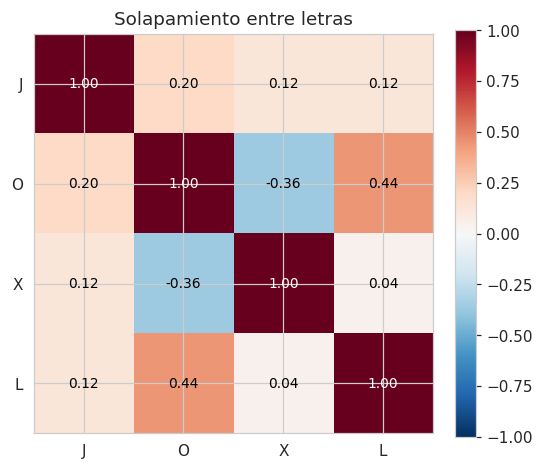


=== Estabilidad de los 4 patrones almacenados (async) ===
  J: punto fijo = True, iteraciones = 1, E = -11.4
  O: punto fijo = True, iteraciones = 1, E = -15.0
  X: punto fijo = True, iteraciones = 1, E = -12.3
  L: punto fijo = True, iteraciones = 1, E = -13.1

Energía de patrones, inversos y mezcla:
  Patrones:  J=-11.4, O=-15.0, X=-12.3, L=-13.1
  Inversos:  -J=-11.4, -O=-15.0, -X=-12.3, -L=-13.1
  Mezcla uniforme: E = -9.4

=== Robustez al ruido (async, 50 trials) ===

 letra  ruido   exact  inverse   spur  iters
     J   0.00    1.00     0.00   0.00   1.00
     J   0.04    1.00     0.00   0.00   2.00
     J   0.08    1.00     0.00   0.00   2.00
     J   0.12    0.98     0.00   0.02   2.04
     J   0.16    0.94     0.00   0.04   2.00
     J   0.20    0.84     0.00   0.14   2.22
     J   0.24    0.74     0.00   0.16   2.24
     J   0.32    0.40     0.00   0.18   2.42
     J   0.40    0.26     0.00   0.14   2.46
     J   0.50    0.04     0.00   0.06   2.38
     O   0.00    1.00     

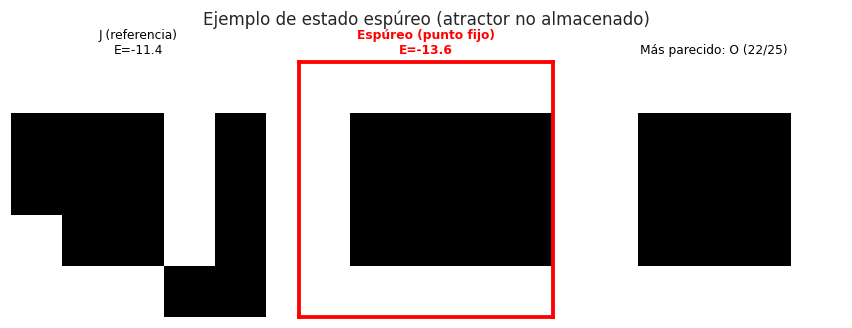

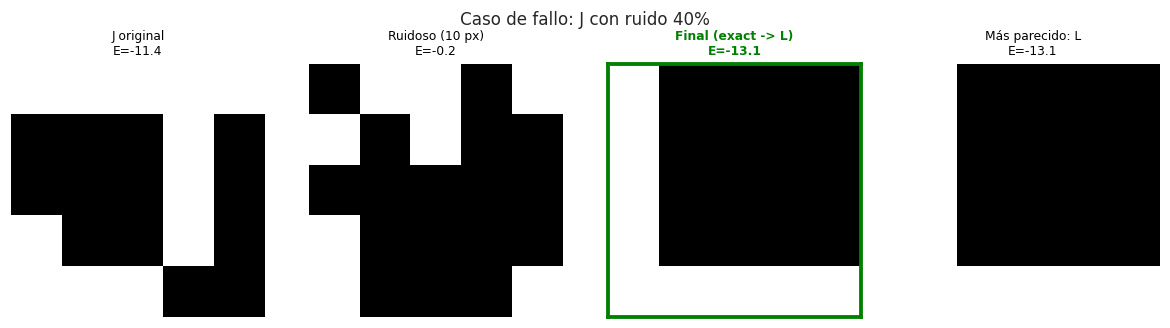

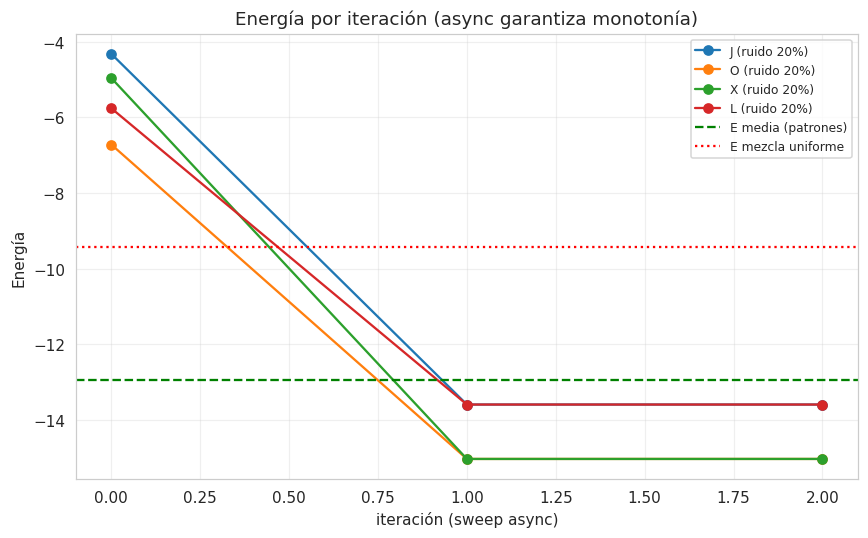


=== Experimento de capacidad (async, ruido 10%) ===

   M   exact_mean  exact_std
   1        1.000      0.000
   2        1.000      0.000
   3        0.703      0.299
   4        0.718      0.235
   5        0.480      0.212
   6        0.453      0.274
   7        0.291      0.168
   8        0.195      0.104
   9        0.156      0.066
  10        0.166      0.017


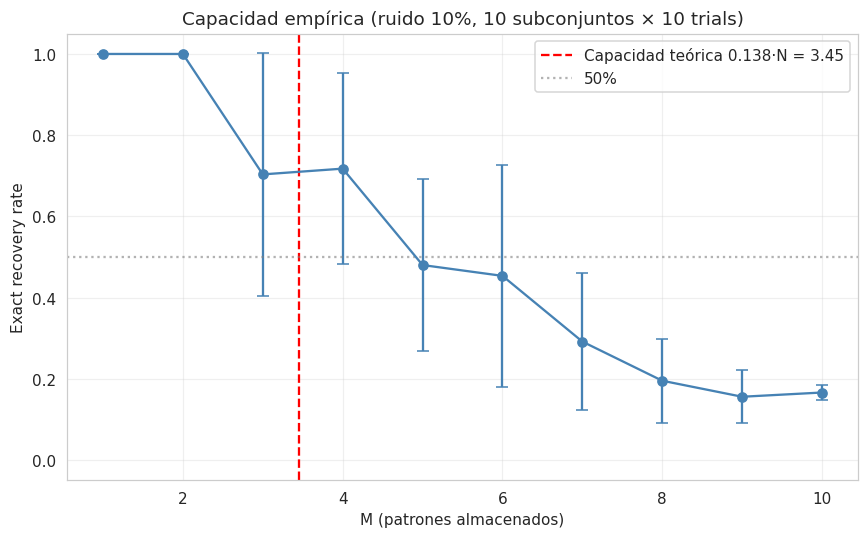


Artefactos guardados en ej6_hopfield_letras.pkl


In [ ]:
# ============================================================
# EJERCICIO 6: Hopfield con letras 5x5
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Definición de un alfabeto 5x5 (para el experimento de capacidad)
# ------------------------------------------------------------
# 5x5 con +1 = negro, -1 = blanco. Solo usamos letras legibles.
LETRAS_5X5 = {
    'J': np.array([
        [ 1, 1, 1, 1, 1],
        [-1,-1,-1, 1,-1],
        [-1,-1,-1, 1,-1],
        [ 1,-1,-1, 1,-1],
        [ 1, 1, 1,-1,-1]]),
    'O': np.array([
        [ 1, 1, 1, 1, 1],
        [ 1,-1,-1,-1, 1],
        [ 1,-1,-1,-1, 1],
        [ 1,-1,-1,-1, 1],
        [ 1, 1, 1, 1, 1]]),
    'X': np.array([
        [ 1,-1,-1,-1, 1],
        [-1, 1,-1, 1,-1],
        [-1,-1, 1,-1,-1],
        [-1, 1,-1, 1,-1],
        [ 1,-1,-1,-1, 1]]),
    'L': np.array([
        [ 1,-1,-1,-1,-1],
        [ 1,-1,-1,-1,-1],
        [ 1,-1,-1,-1,-1],
        [ 1,-1,-1,-1,-1],
        [ 1, 1, 1, 1, 1]]),
    'T': np.array([
        [ 1, 1, 1, 1, 1],
        [-1,-1, 1,-1,-1],
        [-1,-1, 1,-1,-1],
        [-1,-1, 1,-1,-1],
        [-1,-1, 1,-1,-1]]),
    'H': np.array([
        [ 1,-1,-1,-1, 1],
        [ 1,-1,-1,-1, 1],
        [ 1, 1, 1, 1, 1],
        [ 1,-1,-1,-1, 1],
        [ 1,-1,-1,-1, 1]]),
    'U': np.array([
        [ 1,-1,-1,-1, 1],
        [ 1,-1,-1,-1, 1],
        [ 1,-1,-1,-1, 1],
        [ 1,-1,-1,-1, 1],
        [ 1, 1, 1, 1, 1]]),
    'S': np.array([
        [ 1, 1, 1, 1, 1],
        [ 1,-1,-1,-1,-1],
        [ 1, 1, 1, 1, 1],
        [-1,-1,-1,-1, 1],
        [ 1, 1, 1, 1, 1]]),
    'E': np.array([
        [ 1, 1, 1, 1, 1],
        [ 1,-1,-1,-1,-1],
        [ 1, 1, 1, 1,-1],
        [ 1,-1,-1,-1,-1],
        [ 1, 1, 1, 1, 1]]),
    'F': np.array([
        [ 1, 1, 1, 1, 1],
        [ 1,-1,-1,-1,-1],
        [ 1, 1, 1, 1,-1],
        [ 1,-1,-1,-1,-1],
        [ 1,-1,-1,-1,-1]]),
}
N = 25

# Las 4 letras del enunciado
PATRONES_4 = ['J', 'O', 'X', 'L']
P4 = np.array([LETRAS_5X5[c].flatten() for c in PATRONES_4])

print(f"Letras del ejercicio: {PATRONES_4}")
print(f"N = {N} neuronas, M = {len(PATRONES_4)} patrones")

# ------------------------------------------------------------
# 2. Red de Hopfield con actualización async por defecto
# ------------------------------------------------------------
class Hopfield:
    """
    Red de Hopfield clásica: W = (1/N) Σ ξ ξᵀ, diag(W) = 0.
    Async garantiza energía monótona no creciente. Sync puede oscilar
    y se detecta explícitamente (período 2).
    """
    def __init__(self, patterns):
        P_ = np.array(patterns).astype(float)
        self.P = P_
        self.N = P_.shape[1]
        self.M = P_.shape[0]
        self.W = (P_.T @ P_) / self.N
        np.fill_diagonal(self.W, 0.0)

    def energy(self, s):
        return -0.5 * float(s @ self.W @ s)

    def step_async(self, s, rng):
        s = s.copy()
        order = rng.permutation(self.N)
        changes = 0
        for i in order:
            h = float(self.W[i] @ s)
            new_i = 1.0 if h > 0 else (-1.0 if h < 0 else s[i])
            if new_i != s[i]:
                s[i] = new_i
                changes += 1
        return s, changes

    def step_sync(self, s):
        h = self.W @ s
        return np.where(h > 0, 1.0, np.where(h < 0, -1.0, s))

    def predict(self, s0, mode='async', max_iter=50, seed=0):
        """
        Devuelve dict con:
          states: lista de estados [s0, s1, ..., sT]
          status: 'fixed' | 'cycle' | 'max_iter'
          cycle:  None o tupla (idx_inicio_ciclo, periodo)
        """
        s = s0.copy().astype(float)
        rng = np.random.default_rng(seed)
        states = [s.copy()]
        seen = {s.tobytes(): 0}

        for t in range(max_iter):
            if mode == 'async':
                s_new, changes = self.step_async(s, rng)
                states.append(s_new.copy())
                if changes == 0:
                    return {'states': states, 'status': 'fixed', 'cycle': None}
            else:
                s_new = self.step_sync(s)
                states.append(s_new.copy())

            key = s_new.tobytes()
            if key in seen:
                # Ciclo: estado ya visto
                start = seen[key]
                return {'states': states, 'status': 'cycle',
                        'cycle': (start, len(states) - 1 - start)}
            seen[key] = len(states) - 1
            s = s_new

        return {'states': states, 'status': 'max_iter', 'cycle': None}

# ------------------------------------------------------------
# 3. Análisis de ortogonalidad
# ------------------------------------------------------------
overlap = (P4 @ P4.T) / N
print("\n=== Matriz de solapamiento (producto interno / N) ===")
print(f"{'':>6}" + "".join(f"{c:>8s}" for c in PATRONES_4))
for i, c in enumerate(PATRONES_4):
    print(f"{c:>6s}" + "".join(f"{overlap[i,j]:>8.2f}" for j in range(len(PATRONES_4))))

off = overlap.copy(); np.fill_diagonal(off, 0)
off_triu = off[np.triu_indices(len(PATRONES_4), k=1)]
print(f"\nOff-diagonal máximo |·|: {np.abs(off_triu).max():.3f}")
print(f"Off-diagonal medio  |·|: {np.abs(off_triu).mean():.3f}")

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(overlap, cmap='RdBu_r', vmin=-1, vmax=1)
for i in range(len(PATRONES_4)):
    for j in range(len(PATRONES_4)):
        ax.text(j, i, f'{overlap[i,j]:.2f}', ha='center', va='center',
                color='white' if abs(overlap[i,j]) > 0.5 else 'black', fontsize=9)
ax.set_xticks(range(len(PATRONES_4))); ax.set_xticklabels(PATRONES_4)
ax.set_yticks(range(len(PATRONES_4))); ax.set_yticklabels(PATRONES_4)
ax.set_title('Solapamiento entre letras')
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 4. Estabilidad de los patrones almacenados (ruido = 0)
# ------------------------------------------------------------
net = Hopfield(P4)
print("\n=== Estabilidad de los 4 patrones almacenados (async) ===")
for i, c in enumerate(PATRONES_4):
    xi = P4[i]
    out = net.predict(xi, mode='async', seed=0)
    final = out['states'][-1]
    ok = np.array_equal(final, xi)
    print(f"  {c}: punto fijo = {ok}, iteraciones = {len(out['states'])-1}, "
          f"E = {net.energy(xi):.1f}")

# Energías de referencia
E_patrones = {c: net.energy(LETRAS_5X5[c].flatten()) for c in PATRONES_4}
E_inversos = {c: net.energy(-LETRAS_5X5[c].flatten()) for c in PATRONES_4}
E_mezcla = net.energy(np.sign(P4.mean(axis=0)).astype(float))

print("\nEnergía de patrones, inversos y mezcla:")
print(f"  Patrones:  " + ", ".join(f"{c}={E_patrones[c]:.1f}" for c in PATRONES_4))
print(f"  Inversos:  " + ", ".join(f"-{c}={E_inversos[c]:.1f}" for c in PATRONES_4))
print(f"  Mezcla uniforme: E = {E_mezcla:.1f}")

# ------------------------------------------------------------
# 5. Robustez al ruido: async, independiente, con tasa de éxito
# ------------------------------------------------------------
def add_noise(xi, p_noise, rng):
    s = xi.copy()
    n_flip = int(round(p_noise * len(s)))
    if n_flip > 0:
        idx = rng.choice(len(s), n_flip, replace=False)
        s[idx] *= -1
    return s

def clasificar(final, P, nombres):
    """
    Devuelve dict con:
      - exact: nombre del patrón si final == patrón
      - inverse: nombre del patrón si final == -patrón
      - spurious: True si no es ninguno ni su inverso
      - best_match: nombre del patrón más parecido (sin invertir)
      - best_sim:  fracción de coincidencia con best_match
      - hamming_orig: hamming con xi original (se calcula aparte)
    """
    N_ = P.shape[1]
    # Distancias Hamming a cada patrón y su inverso
    d_patron = {nombres[i]: int((final != P[i]).sum()) for i in range(len(nombres))}
    d_inv = {nombres[i]: int((final != -P[i]).sum()) for i in range(len(nombres))}

    for n in nombres:
        if d_patron[n] == 0:
            return {'tipo': 'exact', 'nombre': n, 'best_match': n,
                    'best_sim': 1.0}
        if d_inv[n] == 0:
            return {'tipo': 'inverse', 'nombre': n, 'best_match': n,
                    'best_sim': 1.0}

    # No es ninguno: buscar el más parecido (sin invertir)
    best = min(d_patron, key=d_patron.get)
    sim = 1 - d_patron[best] / N_
    return {'tipo': 'spurious', 'nombre': None, 'best_match': best,
            'best_sim': sim}

def evaluar(net, P, nombres, noise_levels, n_trials=50, mode='async'):
    resultados = []
    for i, nombre in enumerate(nombres):
        xi = P[i]
        for noise in noise_levels:
            exact = inverse = spurious = 0
            iters_list = []
            for trial in range(n_trials):
                rng = np.random.default_rng(
                    hash((nombre, noise, trial)) % 2**32)
                noisy = add_noise(xi, noise, rng)
                out = net.predict(noisy, mode=mode, seed=trial, max_iter=50)
                final = out['states'][-1]
                iters_list.append(len(out['states']) - 1)

                cls = clasificar(final, P, nombres)
                if cls['tipo'] == 'exact' and cls['nombre'] == nombre:
                    exact += 1
                elif cls['tipo'] == 'inverse' and cls['nombre'] == nombre:
                    inverse += 1
                elif cls['tipo'] == 'spurious':
                    spurious += 1
                # 'wrong pattern' (exact de otro nombre) se cuenta como fallo
                # implícitamente: no suma a exact/inverse, y no es spurious
            resultados.append({
                'letra': nombre, 'ruido': noise,
                'exact': exact / n_trials,
                'inverse': inverse / n_trials,
                'spurious': spurious / n_trials,
                'mean_iters': float(np.mean(iters_list))
            })
    return resultados

noise_levels = [0.0, 0.04, 0.08, 0.12, 0.16, 0.20, 0.24, 0.32, 0.40, 0.50]

print("\n=== Robustez al ruido (async, 50 trials) ===")
res_async = evaluar(net, P4, PATRONES_4, noise_levels, n_trials=50, mode='async')

# Tabla imprimible
print(f"\n{'letra':>6s} {'ruido':>6s} {'exact':>7s} {'inverse':>8s} "
      f"{'spur':>6s} {'iters':>6s}")
for r in res_async:
    print(f"{r['letra']:>6s} {r['ruido']:>6.2f} {r['exact']:>7.2f} "
          f"{r['inverse']:>8.2f} {r['spurious']:>6.2f} {r['mean_iters']:>6.2f}")

# ------------------------------------------------------------
# 6. Comparación async vs sync (detección de ciclos)
# ------------------------------------------------------------
print("\n=== Async vs Sync (ruido 20%, 10 trials) ===")
for nombre in PATRONES_4:
    xi = LETRAS_5X5[nombre].flatten()
    exact_async = exact_sync = 0
    cycles_sync = 0
    for trial in range(10):
        rng = np.random.default_rng(hash((nombre, trial)) % 2**32)
        noisy = add_noise(xi, 0.20, rng)
        out_a = net.predict(noisy, mode='async', seed=trial)
        out_s = net.predict(noisy, mode='sync', max_iter=50)
        if np.array_equal(out_a['states'][-1], xi):
            exact_async += 1
        if np.array_equal(out_s['states'][-1], xi):
            exact_sync += 1
        if out_s['status'] == 'cycle':
            cycles_sync += 1
    print(f"  {nombre}: async exact={exact_async}/10  "
          f"sync exact={exact_sync}/10  sync ciclos={cycles_sync}/10")

# ------------------------------------------------------------
# 7. Estado espúreo: búsqueda sistemática
# ------------------------------------------------------------
def es_espurio(s, P, nombres):
    N_ = P.shape[1]
    for i in range(len(nombres)):
        if int((s != P[i]).sum()) == 0 or int((s != -P[i]).sum()) == 0:
            return False, None
    # Además verificamos que sea punto fijo (async con 0 cambios)
    net_local = Hopfield(P)
    out = net_local.predict(s, mode='async', seed=0, max_iter=5)
    return out['status'] == 'fixed', out['states'][-1]

print("\n=== Búsqueda de estados espúreos ===")
espurios_encontrados = []

# (a) Estados fijos obtenidos desde inputs muy ruidosos
for nombre in PATRONES_4:
    xi = LETRAS_5X5[nombre].flatten()
    for noise in [0.40, 0.50, 0.60]:
        for trial in range(20):
            rng = np.random.default_rng(hash((nombre, noise, trial)) % 2**32)
            noisy = add_noise(xi, noise, rng)
            out = net.predict(noisy, mode='async', seed=trial, max_iter=50)
            if out['status'] != 'fixed':
                continue
            final = out['states'][-1]
            es_esp, _ = es_espurio(final, P4, PATRONES_4)
            if es_esp:
                espurios_encontrados.append({
                    'origen': nombre, 'ruido': noise, 'trial': trial,
                    'estado': final.copy(),
                    'E': net.energy(final)
                })
                break  # uno por (origen, ruido)
        if espurios_encontrados and espurios_encontrados[-1]['origen'] == nombre \
                and espurios_encontrados[-1]['ruido'] == noise:
            break

# (b) Búsqueda directa: muestreo aleatorio del hipercubo y ver si alguno es fijo
print("Muestreo aleatorio para encontrar espúreos ...")
rng = np.random.default_rng(0)
espurios_random = []
for _ in range(2000):
    s = rng.choice([-1.0, 1.0], size=N)
    out = net.predict(s, mode='async', seed=0, max_iter=50)
    if out['status'] != 'fixed':
        continue
    final = out['states'][-1]
    es_esp, _ = es_espurio(final, P4, PATRONES_4)
    if es_esp:
        key = final.tobytes()
        if not any(e['estado'].tobytes() == key for e in espurios_random):
            espurios_random.append({'estado': final, 'E': net.energy(final)})
    if len(espurios_random) >= 5:
        break

print(f"\nEspúreos encontrados por ruido fuerte: {len(espurios_encontrados)}")
for e in espurios_encontrados:
    print(f"  origen={e['origen']}, ruido={e['ruido']:.0%}, "
          f"E={e['E']:.1f}, difiere del origen en {(e['estado'] != LETRAS_5X5[e['origen']].flatten()).sum()} px")

print(f"\nEspúreos encontrados por muestreo aleatorio: {len(espurios_random)}")
for e in espurios_random:
    print(f"  E={e['E']:.1f}")

# ------------------------------------------------------------
# 8. Visualización de un espúreo (si hay) y de fallos
# ------------------------------------------------------------
def dibujar(ax, vec, titulo, border_color=None, energy=None):
    ax.imshow(vec.reshape(5, 5), cmap='gray', vmin=-1, vmax=1)
    ax.set_xticks([]); ax.set_yticks([])
    if energy is not None:
        titulo = f"{titulo}\nE={energy:.1f}"
    ax.set_title(titulo, fontsize=8, color=border_color or 'black',
                 fontweight='bold' if border_color else 'normal')
    if border_color:
        for s in ax.spines.values():
            s.set_visible(True); s.set_edgecolor(border_color); s.set_linewidth(2.5)
    else:
        for s in ax.spines.values():
            s.set_visible(False)

# Tomamos un espúreo si existe
if espurios_random:
    ej = espurios_random[0]
    fig, axes = plt.subplots(1, 3, figsize=(8, 3))
    dibujar(axes[0], P4[0], f'J (referencia)', energy=net.energy(P4[0]))
    dibujar(axes[1], ej['estado'], f'Espúreo (punto fijo)',
            border_color='red', energy=ej['E'])
    # comparación con el patrón más parecido
    sims = [(int((ej['estado'] == P4[i]).sum()), PATRONES_4[i])
            for i in range(len(PATRONES_4))]
    sims.sort(reverse=True)
    dibujar(axes[2], P4[PATRONES_4.index(sims[0][1])],
            f'Más parecido: {sims[0][1]} ({sims[0][0]}/25)')
    plt.suptitle('Ejemplo de estado espúreo (atractor no almacenado)', fontsize=11)
    plt.tight_layout(); plt.show()
else:
    print("\nNo se encontraron espúreos en el muestreo. Se muestra el caso de fallo "
          "desde una letra ruidosa.")

# Caso de fallo controlado: J con 40% de ruido
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
xi = LETRAS_5X5['J'].flatten()
rng = np.random.default_rng(1)
noisy = add_noise(xi, 0.40, rng)
out = net.predict(noisy, mode='async', seed=1)
final = out['states'][-1]
cls = clasificar(final, P4, PATRONES_4)
dibujar(axes[0], xi, 'J original', energy=net.energy(xi))
dibujar(axes[1], noisy, f'Ruidoso ({int((noisy != xi).sum())} px)',
        energy=net.energy(noisy))
dibujar(axes[2], final, f"Final ({cls['tipo']} -> {cls['best_match']})",
        border_color='red' if cls['tipo'] != 'exact' else 'green',
        energy=net.energy(final))
# Patrón más parecido
idx_best = PATRONES_4.index(cls['best_match'])
dibujar(axes[3], P4[idx_best], f"Más parecido: {cls['best_match']}",
        energy=net.energy(P4[idx_best]))
plt.suptitle('Caso de fallo: J con ruido 40%', fontsize=11)
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 9. Energía por iteración (async): ejemplo
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))
for nombre in PATRONES_4:
    xi = LETRAS_5X5[nombre].flatten()
    rng = np.random.default_rng(3)
    noisy = add_noise(xi, 0.20, rng)
    out = net.predict(noisy, mode='async', seed=3)
    energies = [net.energy(s) for s in out['states']]
    ax.plot(range(len(energies)), energies, marker='o', label=f'{nombre} (ruido 20%)')
# Referencias
ax.axhline(np.mean(list(E_patrones.values())), color='green', ls='--',
            label='E media (patrones)')
ax.axhline(E_mezcla, color='red', ls=':', label='E mezcla uniforme')
ax.set_xlabel('iteración (sweep async)'); ax.set_ylabel('Energía')
ax.set_title('Energía por iteración (async garantiza monotonía)')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 10. Capacidad: experimento empírico
# ------------------------------------------------------------
print("\n=== Experimento de capacidad (async, ruido 10%) ===")
todas_letras = list(LETRAS_5X5.keys())
max_M = min(len(todas_letras), 10)
capacidad_res = []
rng = np.random.default_rng(0)

for M in range(1, max_M + 1):
    # 10 subconjuntos distintos de tamaño M
    sub_exact = []
    for sub in range(10):
        elegidas = list(rng.choice(todas_letras, size=M, replace=False))
        P_ = np.array([LETRAS_5X5[c].flatten() for c in elegidas])
        net_ = Hopfield(P_)
        exact_count = 0
        total = 0
        for c in elegidas:
            xi = LETRAS_5X5[c].flatten()
            for trial in range(10):
                rng2 = np.random.default_rng(hash((c, M, sub, trial)) % 2**32)
                noisy = add_noise(xi, 0.10, rng2)
                out = net_.predict(noisy, mode='async', seed=trial)
                final = out['states'][-1]
                total += 1
                if np.array_equal(final, xi):
                    exact_count += 1
        sub_exact.append(exact_count / total)
    capacidad_res.append({'M': M, 'exact_mean': np.mean(sub_exact),
                           'exact_std': np.std(sub_exact)})

print(f"\n{'M':>4s} {'exact_mean':>12s} {'exact_std':>10s}")
for r in capacidad_res:
    print(f"{r['M']:>4d} {r['exact_mean']:>12.3f} {r['exact_std']:>10.3f}")

Ms = [r['M'] for r in capacidad_res]
means = [r['exact_mean'] for r in capacidad_res]
stds = [r['exact_std'] for r in capacidad_res]

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(Ms, means, yerr=stds, marker='o', capsize=4, color='steelblue')
ax.axvline(0.138 * N, color='red', ls='--',
            label=f'Capacidad teórica 0.138·N = {0.138*N:.2f}')
ax.axhline(0.5, color='gray', ls=':', alpha=0.6, label='50%')
ax.set_xlabel('M (patrones almacenados)'); ax.set_ylabel('Exact recovery rate')
ax.set_ylim(-0.05, 1.05); ax.grid(alpha=0.3)
ax.set_title('Capacidad empírica (ruido 10%, 10 subconjuntos × 10 trials)')
ax.legend()
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 11. Guardar artefactos
# ------------------------------------------------------------
import joblib
joblib.dump({
    'LETRAS_5X5': LETRAS_5X5,
    'PATRONES_4': PATRONES_4,
    'P4': P4,
    'W': net.W,
    'E_patrones': E_patrones,
    'E_mezcla': E_mezcla,
    'res_async': res_async,
    'capacidad_res': capacidad_res,
    'espurios_random': espurios_random,
}, 'ej6_hopfield_letras.pkl')
print("\nArtefactos guardados en ej6_hopfield_letras.pkl")